# TweetToxic · Detección de odio, objetivo y agresividad en tuits en español

**Equipo:** NLP_Grupo3 (NLP_G3) · Maestría en Inteligencia Artificial, Pontificia Universidad Javeriana

**Integrantes:** Juan Sebastián Bravo, Javier Chaparro, Tannia Hernández, Oscar Arias, Jacobo Orozco
## Resumen ejecutivo

**Tarea.** Se abordó una clasificación multietiqueta de tuits en español con tres etiquetas binarias:
- **HS**: discurso de odio;
- **TR**: el mensaje va dirigido a una persona concreta (1) o a un grupo (0);
- **AG**: agresividad.

**Métrica:** F1 macro por columnas, es decir, la media del F1 de las tres etiquetas.

**Solución final.** Se construyó un ensamble de 14 modelos propios, entrenados desde cero y sin ningún componente preentrenado:
- modelos lineales sobre TF-IDF;
- Naive Bayes, árboles y boosting;
- redes CNN y MLP.

Además del train de la competencia, se usaron **3621 tuits del corpus HatEval**, con autorización del profesor. HatEval se deduplicó estrictamente contra el train y el test, y del test no se usó nunca ni el texto ni las etiquetas.

**Cifras clave** (todas se recalculan o se comprueban en este notebook):

| | Valor |
|---|---|
| Validación cruzada del envío principal (H5_quote) | F1 macro **0.8216** (`folds.csv`) y **0.8275** (`folds_seed2`) |
| Mejor puntaje público | **0.81235** (H1_quote) |
| Progresión en el leaderboard público | 0.7746 (primer modelo lineal) → 0.7860 (ensamble + regla de comillas) → **0.8124** (con HatEval) |

**Organización del notebook:**
- Las secciones 3–11 resumen el proyecto: análisis exploratorio, preprocesamiento, validación, diseño experimental, ensamble, regla del artefacto, datos externos, selección y errores.
- Junto a las cifras recalculadas aquí, se muestran las figuras exportadas por los notebooks de origen (01–11), entregados aparte en el Campus Virtual. Allí está el código completo de cada experimento.
- **Modo FAST** (por defecto, unos minutos): recalcula las cifras de validación desde las predicciones guardadas y regenera los 10 envíos. Comprueba con `assert` que coinciden con lo registrado y con lo enviado.
- **Modo FULL** (opcional): reentrena el envío principal desde los datos crudos.

## 1. Configuración

**Modos:**
- **`FAST`** (por defecto, objetivo < 10 min en la CPU de Kaggle):
  - no entrena nada ni deserializa modelos (`.joblib`/`.pt`): lee solo CSV, parquet y JSON;
  - recalcula la validación cruzada desde las predicciones fuera de fold guardadas;
  - regenera los 10 envíos y escribe `submission.csv`.
- **`SMOKE`:** recorre el camino de `FULL` con 1 fold, 1 semilla y una submuestra, solo para comprobar que el código corre (≈5–10 min). Requiere el token de Hugging Face.
- **`FULL`:** reentrena H5_quote desde los datos crudos con las mismas funciones del proyecto (≈5–6 h en CPU, 12). Requiere Internet y el secreto `HF_TOKEN`.

**Rutas:**
- en Kaggle: los datos de la competencia y el dataset de artefactos `tweettoxic-nlp-grupo3-artifacts` se leen de `/kaggle/input/`, y las salidas se escriben en `/kaggle/working/`;
- fuera de Kaggle: se usan las carpetas del repositorio.

**Reproducibilidad:** semilla única `SEED = 42` (definida en `common.py`), folds guardados y versiones de las librerías impresas abajo.

In [1]:
%matplotlib inline
import os
import sys
import time
import warnings
from pathlib import Path

MODE = "FAST"  # "FAST" (por defecto) | "SMOKE" | "FULL"
MODE = os.environ.get("TT_MODE", MODE)
T0 = time.perf_counter()
warnings.filterwarnings("ignore")

INPUT = Path(os.environ.get("TT_KAGGLE_INPUT", "/kaggle/input"))
IS_KAGGLE = INPUT.exists()


def find_dir(root, test, depth=3):
    """Primera carpeta bajo root (hasta `depth` niveles) que cumple test(carpeta)."""
    for level in range(1, depth + 1):
        for p in sorted(root.glob("/".join(["*"] * level))):
            if p.is_dir() and test(p):
                return p
    return None


if IS_KAGGLE:
    ART = find_dir(INPUT, lambda p: (p / "src" / "kaggle_support.py").exists())
    WORK = Path(os.environ.get("TT_KAGGLE_WORKING", "/kaggle/working"))
    COMP_CANDIDATES = [p for p in sorted(INPUT.glob("*")) + sorted(INPUT.glob("*/*")) if p.is_dir() and p != ART]
else:  # fuera de Kaggle: rutas del repositorio (el notebook vive en kaggle/notebook/)
    REPO = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebook" else Path.cwd().resolve()
    ART, WORK, COMP_CANDIDATES = REPO / "kaggle" / "dataset", REPO / "kaggle" / "working", [REPO / "data"]
assert ART is not None, "No se encontró el dataset de artefactos: añade 'tweettoxic-nlp-grupo3-artifacts' como input"
WORK.mkdir(parents=True, exist_ok=True)
os.environ["TWEETTOXIC_MODELS_DIR"] = str(WORK / "models")            # lo que entrene FULL va a /kaggle/working
os.environ["TWEETTOXIC_SUBMISSIONS_DIR"] = str(WORK / "submissions_full")
sys.dont_write_bytecode = True  # no escribir __pycache__ dentro del dataset (en Kaggle es de solo lectura)
sys.path.insert(0, str(ART / "src"))
os.environ["PYTHONPATH"] = str(ART / "src") + os.pathsep + os.environ.get("PYTHONPATH", "")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Image, Markdown, display

import common
import ensemble as en
import handcrafted as hf
import kaggle_support as ks
import modeling as md
import preprocessing as pp
from common import LABELS, SEED, _near_duplicate_key


def is_competition_dir(p):
    try:
        return bool(ks.find_competition_files(p))
    except FileNotFoundError:
        return False


COMP = next(p for p in COMP_CANDIDATES if is_competition_dir(p))
train, test, FILES = ks.load_competition(COMP)
art = ks.Artifacts(ART, train, test)
Y = train[LABELS].to_numpy()
texts = train["text"]
EMPTY_TR, QUOTED, QUOTED_TE = md.empty_mask(texts), md.quoted_mask(texts), md.quoted_mask(test["text"])
FIG = ART / "reports" / "figures"
REG = art.registry


def show(name, width=900):
    """Figura exportada por el notebook de origen (reports/figures/ del proyecto)."""
    display(Image(filename=str(FIG / name), width=width))


pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 30)
COLORS = {"HS": "#2a78d6", "TR": "#eb6834", "AG": "#1baf7a", "gris": "#8a8f98"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

print(f"Modo: {MODE} | entorno: {'Kaggle' if IS_KAGGLE else 'local (repositorio)'} | SEED = {SEED}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")
print(f"Competición: {', '.join(p.name for p in FILES.values())} | train {len(train)} tuits, test {len(test)}")
print(f"Artefactos: {ART.name} | {len(REG)} modelos en el registro | {len(art.ensembles)} envíos seleccionados")
print("Tiempo esperado: FAST ≈ 2–5 min | SMOKE ≈ 5–10 min | FULL ≈ 5–6 h (CPU)")

Modo: FAST | entorno: Kaggle | SEED = 42
Python 3.11.15 | numpy 1.26.4 | pandas 2.2.3 | scikit-learn 1.2.2 | scipy 1.11.4 | matplotlib 3.7.5
Competición: toxic_test.csv, toxic_train.csv | train 1731 tuits, test 1154
Artefactos: tweettoxic-nlp-grupo3-artifacts | 235 modelos en el registro | 10 envíos seleccionados
Tiempo esperado: FAST ≈ 2–5 min | SMOKE ≈ 5–10 min | FULL ≈ 5–6 h (CPU)


## 2. Problema, métrica y reglas

**Datos:** 1731 tuits de entrenamiento con las tres etiquetas y 1154 de test sin etiquetas. El separador del CSV es `;`.

**Métrica: F1 macro por columnas.**
- El **F1** de una etiqueta es la media armónica de la precisión (de los tuits marcados como positivos, cuántos lo son) y de la exhaustividad (de los positivos reales, cuántos se marcan).
- El **F1 macro** es la media simple de los tres F1. Cada etiqueta pesa lo mismo aunque tenga menos positivos.

**Cumplimiento de las reglas de TweetToxic** (*"No se permite utilizar modelos de lenguaje, embeddings, clasificadores o transformers preentrenados"*):

| Componente | Qué se usó | Entrenado por el equipo |
|---|---|---|
| Representación | TF-IDF de palabras y de caracteres; Word2Vec propio (gensim) | Sí, dentro de cada fold |
| Clasificadores | Regresión logística, SVM lineal, NB-SVM, Naive Bayes, ExtraTrees, XGBoost | Sí |
| Redes | MLP, CNN de palabras y de caracteres (PyTorch) | Sí, desde pesos aleatorios |
| Transformer | Encoder pequeño con tokenizador BPE propio (notebook 06) | Sí, desde cero (tokenizador incluido) |
| spaCy `es_core_news_sm` | Solo `lemma_`, `pos_` y `morph`, en el análisis exploratorio y en una variante de preprocesamiento | No interviene en la predicción final; **sin vectores** (el modelo `sm` no trae ninguno) |
| Corpus externo | HatEval (etiquetado), deduplicado | Solo sus datos; uso autorizado por el profesor |

**Lo que se evitó:** `from_pretrained`, la librería `transformers`, los vectores de spaCy (`token.vector`, `doc.vector`), GloVe o fastText preentrenados, y cualquier entrenamiento con el texto del test. La celda siguiente lo comprueba sobre el código del proyecto.

In [2]:
import re

patterns = {"from_pretrained": r"from_pretrained", "librería transformers": r"^\s*(import|from)\s+transformers",
            "AutoModel/AutoTokenizer": r"AutoModel|AutoTokenizer", "vectores de spaCy (token/doc.vector, similarity)": r"\.vector\b|\.similarity\(",
            "pesos preentrenados (torch.hub, gensim downloader)": r"torch\.hub|gensim\.downloader|KeyedVectors\.load"}
src_files = sorted((ART / "src").glob("*.py"))
hits = {name: [f"{f.name}:{i}" for f in src_files for i, line in enumerate(f.read_text().splitlines(), 1)
               if re.search(rx, line) and not line.lstrip().startswith("#")] for name, rx in patterns.items()}
display(pd.DataFrame({"patrón": list(hits), "coincidencias en src/": [len(v) for v in hits.values()]}).set_index("patrón"))
assert not any(hits.values()), hits
guard = [f"{f.name}:{i}" for f in src_files for i, line in enumerate(f.read_text().splitlines(), 1) if "vectors.shape[0] == 0" in line]
print(f"Revisados {len(src_files)} módulos: ningún componente preentrenado. Además, {', '.join(guard)} comprueba al cargar spaCy "
      "que el modelo no trae vectores (assert nlp.vocab.vectors.shape[0] == 0).")

,coincidencias en src/
patrón,
from_pretrained,0
librería transformers,0
AutoModel/AutoTokenizer,0
"vectores de spaCy (token/doc.vector, similarity)",0
"pesos preentrenados (torch.hub, gensim downloader)",0


Revisados 10 módulos: ningún componente preentrenado. Además, preprocessing.py:265 comprueba al cargar spaCy que el modelo no trae vectores (assert nlp.vocab.vectors.shape[0] == 0).


**Recursos externos y licencias** (detalle en las referencias, 13):

| Recurso | Uso | Licencia |
|---|---|---|
| HatEval, SemEval-2019 Task 5 (Basile et al., 2019), parte en español | 3621 tuits etiquetados para entrenar (9) | CC BY-NC 4.0 |
| spaCy 3.8 + `es_core_news_sm` 3.8.0 | Lemas, categorías gramaticales y morfología (análisis exploratorio y variante V4) | MIT / GPL 3.0 |
| scikit-learn, PyTorch, gensim, XGBoost, LightGBM, `tokenizers` | Librerías para entrenar desde cero | BSD-3 / BSD-3 / LGPL-2.1 / Apache-2.0 / MIT / Apache-2.0 |
| Léxicos de insultos, imperativos y segunda persona; diccionario de restauración de palabras | Construidos por el equipo, a mano o desde el train sin etiquetas | Propios |

## 3. Análisis exploratorio

Se resumen los hallazgos que condicionaron decisiones posteriores. Algunas cifras se recalculan en vivo y otras se muestran con las figuras exportadas por el notebook **01_EDA**, que contiene el análisis completo.

### 3.1 Etiquetas y jerarquía

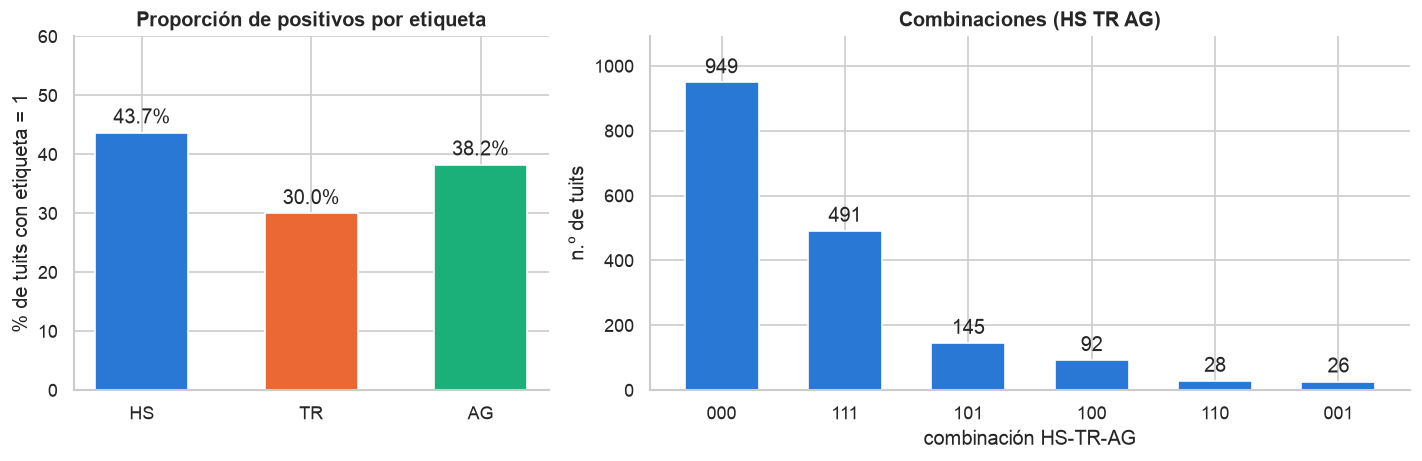

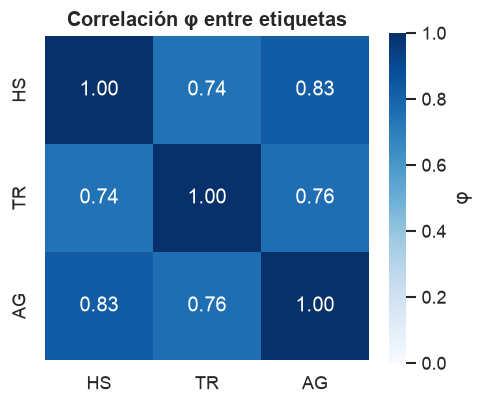

Recalculado aquí: HS 43.7%, TR 30.0%, AG 38.2% | TR=1 ⇒ HS=1: 1.000 | AG=1 ⇒ HS=1: 0.961 | combinaciones 010 y 011: 0


In [3]:
show("01_label_distribution.png", 900)
show("01_label_phi.png", 330)
combo = pd.Series(["".join(map(str, r)) for r in Y])
print(f"Recalculado aquí: HS {Y[:, 0].mean():.1%}, TR {Y[:, 1].mean():.1%}, AG {Y[:, 2].mean():.1%} | "
      f"TR=1 ⇒ HS=1: {(Y[Y[:, 1] == 1, 0] == 1).mean():.3f} | AG=1 ⇒ HS=1: {(Y[Y[:, 2] == 1, 0] == 1).mean():.3f} | "
      f"combinaciones 010 y 011: {int(combo.isin(['010', '011']).sum())}")

**Interpretación:**
- **Ninguna etiqueta está muy desbalanceada:** HS 43.7%, TR 30.0% y AG 38.2%.
- **Las combinaciones están muy concentradas:** 000 (949 tuits) y 111 (491) suman el 83%. Las combinaciones con odio pero sin todas las etiquetas (101, 100, 110) son minoritarias.
- **Hay una jerarquía clara:** TR=1 implica siempre HS=1 (1.000), y nunca aparecen 010 ni 011.
  - Por eso el posprocesamiento fuerza **TR=0 cuando se predice HS=0**.
- **AG=1 implica HS=1 en el 96.1%.** Las excepciones son las 26 filas 001, que se explican en 3.5.
- **Las etiquetas están muy correlacionadas** (φ de 0.74 a 0.83, la más alta entre HS y AG). Más adelante, un ensamble que mira las 3 etiquetas a la vez lo aprovecha (7).

### 3.2 Longitud y rasgos superficiales

Se midieron la longitud de cada tuit y la presencia de menciones, enlaces, hashtags, alargamientos, risas y mayúsculas en cada clase.

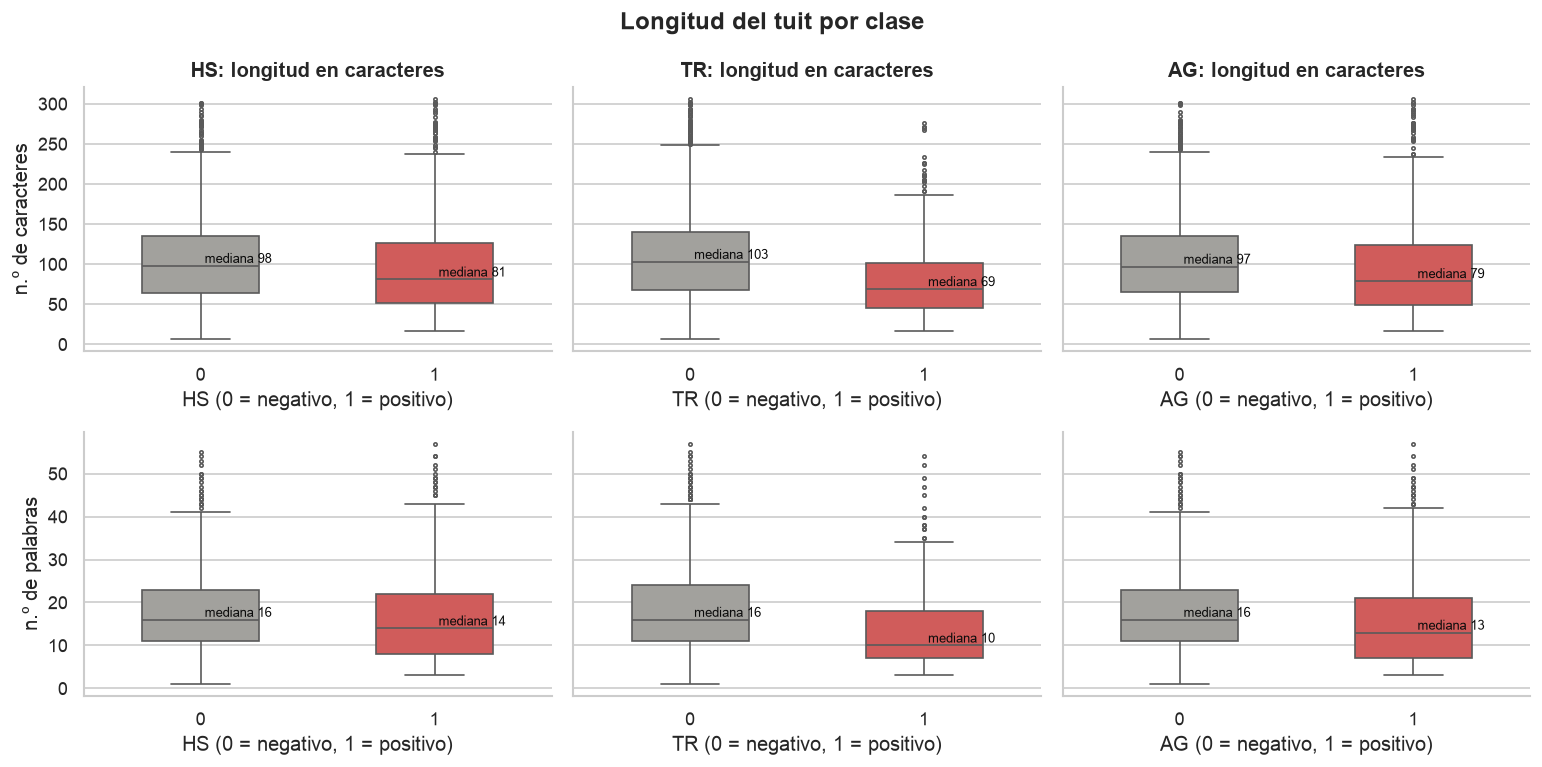

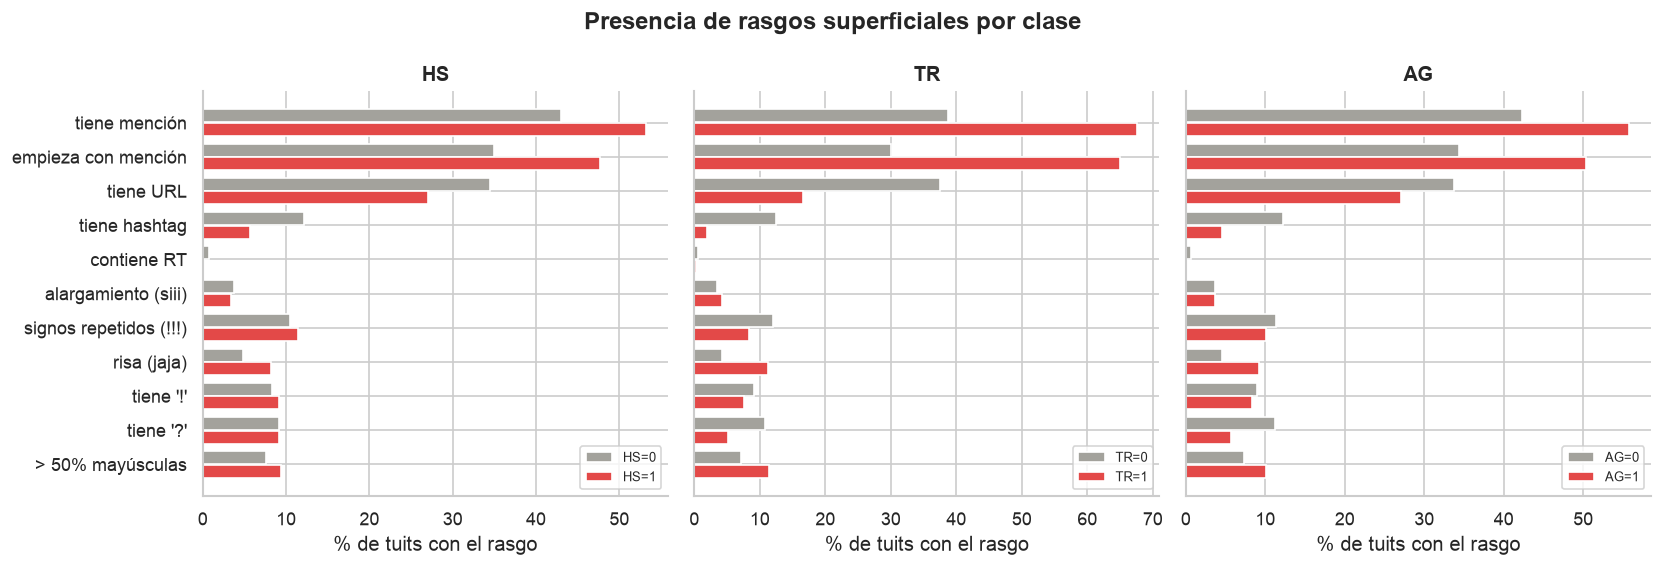

,% empieza con mención,longitud mediana,% con URL
TR,,,
0,30.0,103.0,37.5
1,64.9,69.0,16.6


In [4]:
show("01_length_by_label.png", 950)
show("01_surface_features_by_label.png", 950)
starts_mention = texts.str.match(r"\s*@").to_numpy()
length = texts.str.len().to_numpy()
prof = pd.DataFrame({"TR": Y[:, 1], "empieza con mención": starts_mention, "longitud": length, "URL": texts.str.contains("http").to_numpy()})
display(prof.groupby("TR").agg(**{"% empieza con mención": ("empieza con mención", lambda s: round(100 * s.mean(), 1)),
                                  "longitud mediana": ("longitud", "median"), "% con URL": ("URL", lambda s: round(100 * s.mean(), 1))}))

**Interpretación:**
- **TR=1 es una respuesta corta a una persona:**
  - el 64.9% empieza con una mención (30.0% en TR=0);
  - la longitud mediana es de 69 caracteres (103 en TR=0);
  - casi no lleva enlaces (16.6% frente a 37.5%) ni hashtags.
- **HS=1 y AG=1 también son algo más cortos** (medianas de 81 y 79 caracteres, frente a 98 y 97) y empiezan más a menudo con mención.
- **Los alargamientos de letras son raros** (≈3–4% en todas las clases) y no distinguen nada. Las risas y las mayúsculas aparecen algo más en las clases positivas.
- **Consecuencia:** las menciones y los enlaces se conservaron como tokens (`<USER>`, `<URL>`) en lugar de borrarlos, porque son señal de TR.

### 3.3 Vocabulario: qué palabras distinguen cada clase

**Log-odds con prior informativo:** para cada palabra se comparan sus frecuencias en la clase positiva y en la negativa, con un prior que estabiliza las palabras raras. El z-score indica cuán asociada está la palabra a la clase positiva; la línea vertical marca z = 1.96.

**Léxico de insultos:** el equipo definió a mano 19 grupos de insultos y 5 de términos despectivos hacia colectivos. Se usaron para el diagnóstico y como rasgos opcionales (`handcrafted.py`).

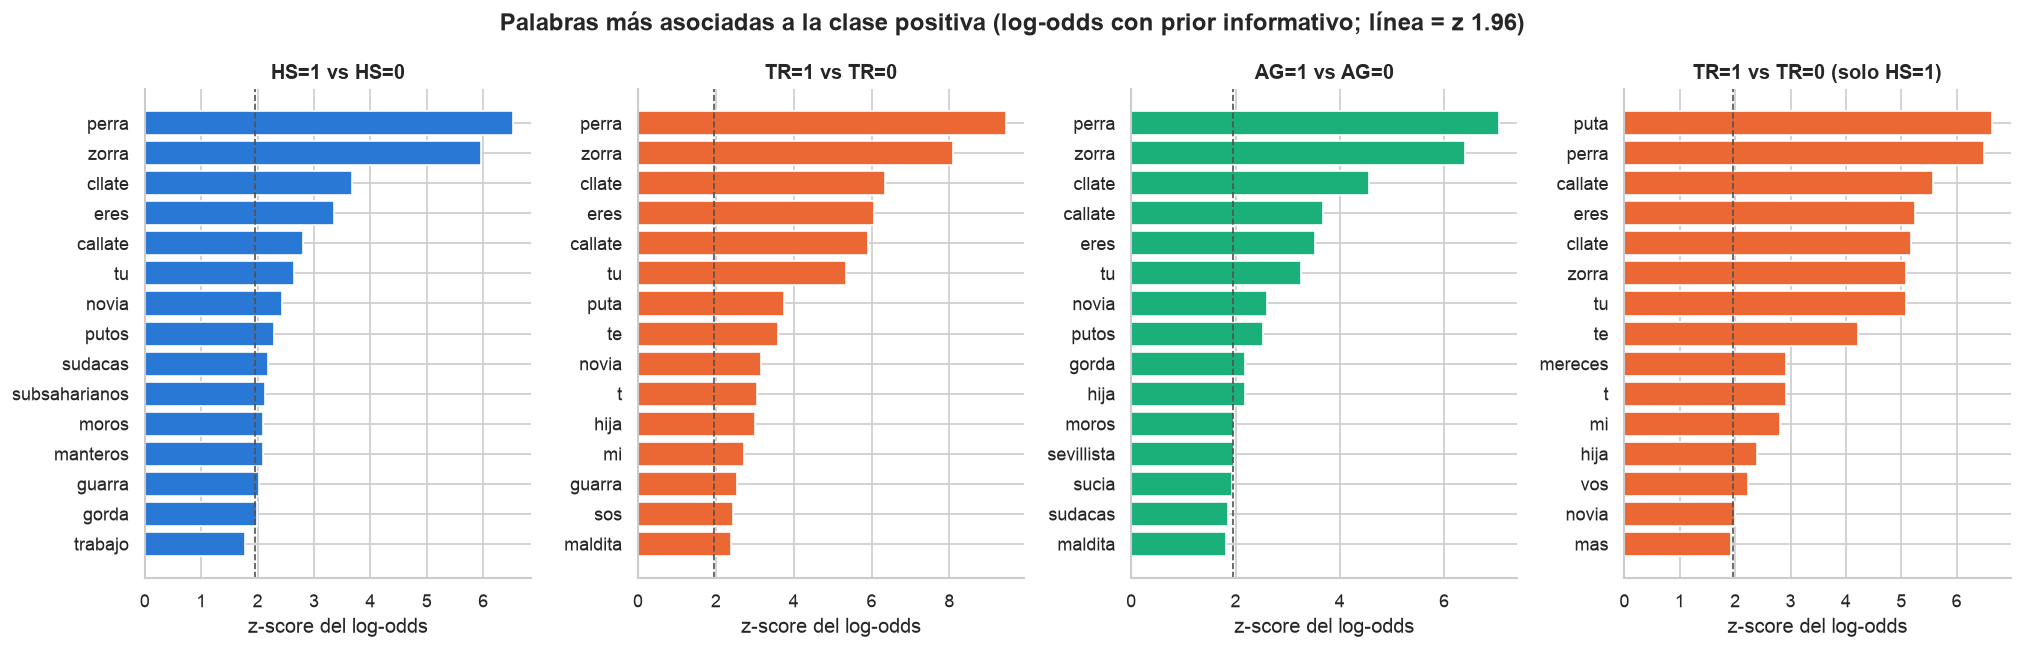

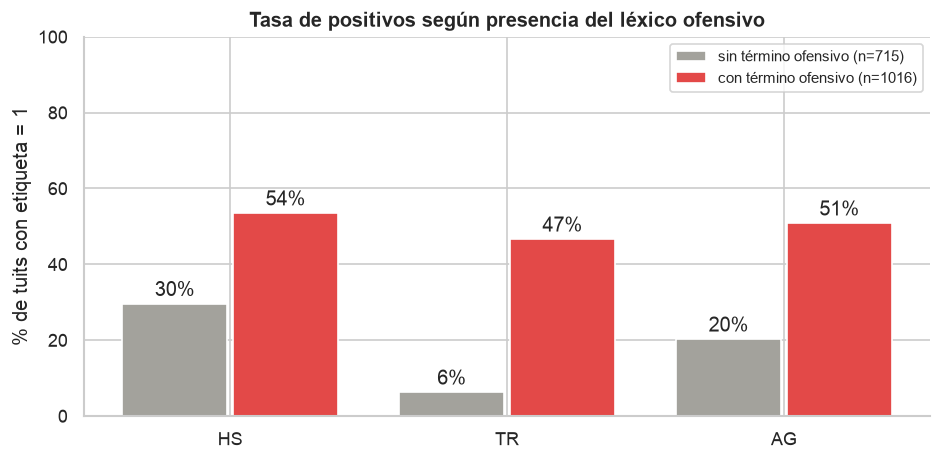

palabra (o plural),zorra,perra,puta,sudaca,negrata
tuits,119,225,559,32,9
% HS=1,89.1,78.7,38.6,84.4,88.9


Con algún insulto del léxico: 56.7% de los tuits | de ellos, HS=1: 52.5% | de los HS=1, con insulto: 68.3% | de los TR=1, con insulto: 90.0%


In [5]:
show("01_log_odds_unigrams.png", 1000)
show("01_lexicon_rates.png", 650)
clean = texts.map(lambda t: pp.lowercase(pp.clean_text(t)))
has_insult = clean.map(lambda t: any(rx.search(t) for rx in hf._INSULT_RX.values())).to_numpy()
rows = []
for w in ["zorra", "perra", "puta", "sudaca", "negrata"]:
    m = clean.str.contains(rf"\b{w}s?\b").to_numpy()  # singular o plural
    rows.append({"palabra (o plural)": w, "tuits": str(int(m.sum())), "% HS=1": f"{100 * Y[m, 0].mean():.1f}"})
display(pd.DataFrame(rows).set_index("palabra (o plural)").T)
print(f"Con algún insulto del léxico: {has_insult.mean():.1%} de los tuits | de ellos, HS=1: {Y[has_insult, 0].mean():.1%} | "
      f"de los HS=1, con insulto: {has_insult[Y[:, 0] == 1].mean():.1%} | de los TR=1, con insulto: {has_insult[Y[:, 1] == 1].mean():.1%}")

**Interpretación:**
- **El odio depende del objetivo del insulto, no del insulto en sí:** *zorra* da 89.1% de HS, *sudaca* 84.4% y *negrata* 88.9%, pero *puta* solo 38.6%, por debajo de la tasa base. Insultos a mujeres e inmigrantes frente a insultos genéricos.
- **TR se asocia a plantillas de respuesta directa:** "cállate + insulto" (*cllate*, *callate*), "eres + insulto" (*eres*, *tu*, *te*). Dentro de los tuits con odio, TR=0 se asocia a plurales y colectivos (*los*, *inmigrantes*, *rabes*), y HS a los colectivos (*sudacas*, *moros*, *subsaharianos*, *manteros*).
- **Los insultos no bastan:**
  - el 56.7% de los tuits tiene alguno, pero de ellos solo el 52.5% es odio;
  - el 31.7% de los HS=1 no tiene ningún insulto del léxico (estereotipos sin palabras ofensivas);
  - en cambio, el 90.0% de los TR=1 sí lo tiene: sin término ofensivo, solo el 6% de los tuits es TR=1.
- La anotación sigue el esquema de HatEval: odio contra **mujeres e inmigrantes**, no cualquier ofensa. **Este es el error dominante del modelo final** (11).

### 3.4 Análisis lingüístico con spaCy

Se analizaron con spaCy (`es_core_news_sm`; solo lemas, categorías gramaticales y morfología, sin vectores) las categorías gramaticales por clase, los imperativos, la segunda persona y la calidad de los lemas.

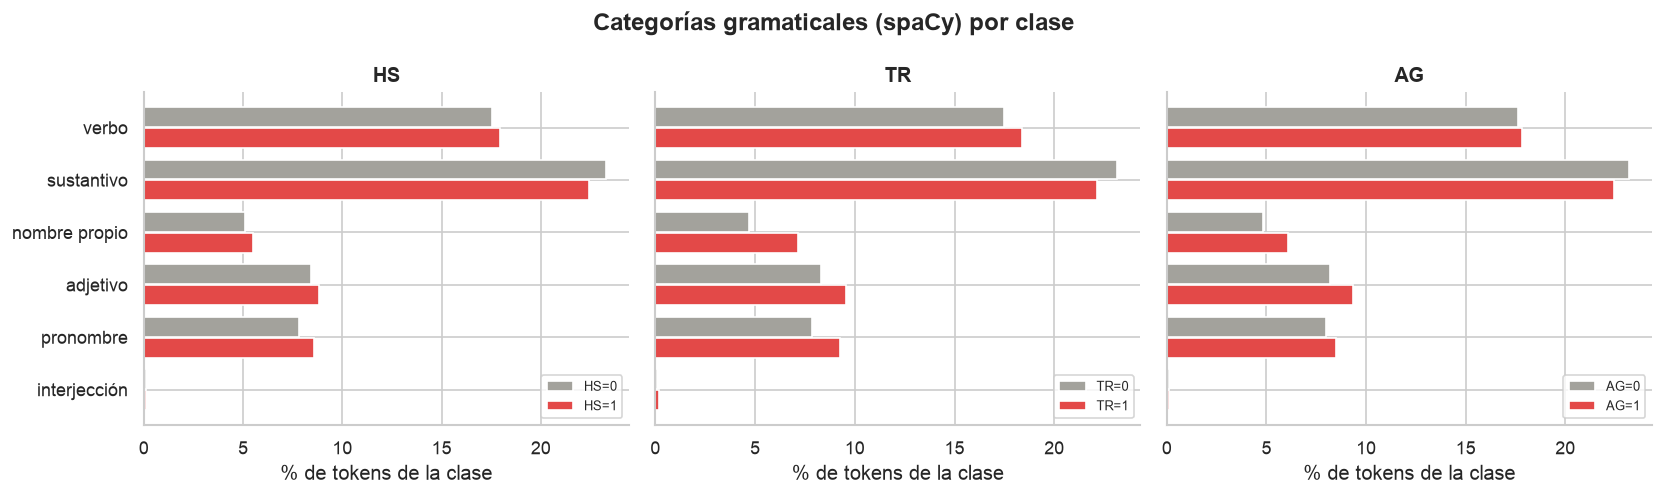

In [6]:
show("01_pos_by_label.png", 950)

**Interpretación:**
- **Las categorías gramaticales apenas separan las clases:** TR=1 tiene algo más de nombres propios (≈7% frente a ≈5% de los tokens), por las menciones, y algo más de pronombres y adjetivos.
- **Imperativo y segunda persona sí distinguen TR:**
  - medido con un léxico propio, el imperativo aparece en el 45.3% de los tuits TR=1, frente al 13.7% de los TR=0 (×3.3). También es más frecuente en AG (×2.3) y en HS (×1.8);
  - la segunda persona (*eres*, *tú*, *te*) multiplica por 2.15 la tasa de TR.
- **La morfología de spaCy no sirve para el imperativo:** `Mood=Imp` solo aparece en el 2.9% de los tuits, porque *callate* sale como sustantivo o como un verbo inventado (*callatar*). En cambio, su marca de segunda persona (`Person=2`) sí funciona (TR ×1.78).
- **Los lemas son poco fiables con este texto:**
  - el 3.5% de los tokens tiene una forma dañada por el borrado de caracteres (3.5), y spaCy inventa lemas como *cllatar*, *perrar* o *rabir*;
  - restaurar antes las tildes reduce los tokens dañados al 0.9%, pero el lema sigue mal;
  - los lemas reducen el vocabulario un 14.5% sin discriminar mejor que las palabras (*eres*, muy asociada a TR, se diluye en *ser*).
- **Consecuencias:** los rasgos de imperativo y segunda persona se construyeron con léxico propio, no con la morfología de spaCy. Los lemas quedaron como una variante opcional (V4), que no mejoró (4).

### 3.5 Artefactos del archivo

**El artefacto de comillas.** En el CSV, los textos que contienen `;` o `"` van entre comillas. Se revisó la etiqueta AG de esas filas.

In [7]:
q = pd.DataFrame({"comillas": np.where(QUOTED, "con ; o \"", "sin"), "AG": Y[:, 2], "combinación": combo})
display(q.groupby("comillas").agg(tuits=("AG", "size"), **{"% AG=1": ("AG", lambda s: round(100 * s.mean(), 1))}))
print("Combinaciones de las filas con comillas:", q.loc[QUOTED, "combinación"].value_counts().to_dict(),
      f"| tuits con comillas en el test: {QUOTED_TE.sum()}")

,tuits,% AG=1
comillas,,
"con ; o """,51,100.0
sin,1680,36.4


Combinaciones de las filas con comillas: {'001': 26, '101': 21, '111': 4} | tuits con comillas en el test: 34


**Interpretación:**
- **Las 51 filas con `;` o `"` tienen AG=1 en el 100%**, frente al 36.4% del resto.
- **Incluyen las 26 filas 001 (agresividad sin odio), que son titulares neutros.** Es un patrón del archivo, no del lenguaje: sin estas filas, AG=1 implicaría siempre HS=1.
- En el test hay 34 filas así. (8) explica cómo se usó y cómo se validó.

**Caracteres borrados.** Se compararon formas de una misma palabra con y sin tildes:

In [8]:
words = pd.Series(" ".join(texts.str.lower()).split())
pairs = [("espaa", "españa", "espana"), ("cllate", "cállate", "callate"), ("rabe", "árabe", "arabe"), ("gero", "güero", "guero")]
display(pd.DataFrame([{"forma dañada": a, "frecuencia": int((words == a).sum()), "forma correcta": b,
                       "frecuencia ": int((words == b).sum()), "sin tilde": c, "frecuencia  ": int((words == c).sum())}
                      for a, b, c in pairs]).set_index("forma dañada"))
non_ascii_tr = texts.map(lambda t: not t.isascii()).sum()
non_ascii_te = test["text"].map(lambda t: not t.isascii()).sum()
print(f"Tuits con algún carácter no ASCII: train {non_ascii_tr}, test {non_ascii_te} "
      f"(en el test: {test.loc[test['text'].map(lambda t: not t.isascii()), 'text'].unique().tolist()})")

,frecuencia,forma correcta,frecuencia,sin tilde,frecuencia
forma dañada,,,,,
espaa,23,españa,0,espana,1
cllate,152,cállate,0,callate,208
rabe,55,árabe,0,arabe,32
gero,28,güero,0,guero,0


Tuits con algún carácter no ASCII: train 0, test 6 (en el test: ['#¿NOMBRE?'])


**Interpretación:**
- **El train perdió todos los caracteres no ASCII** (tildes, ñ, ü, ¿): *cllate* aparece 152 veces y *cállate*, 0.
- **El carácter se borra, no se sustituye.** Por eso *cllate* (152) y *callate* (208) son dos "palabras" distintas para un modelo de palabras. Al menos 205 palabras distintas parecen dañadas y aparecen en el 43.3% de los tuits.
- **Decisiones:**
  - a todo texto externo se le aplica el mismo borrado;
  - los n-gramas de caracteres absorben gran parte de esa fragmentación;
  - la restauración de palabras (V3) se probó como variante (4).
- **El test tampoco tiene tildes:** sus 6 tuits con caracteres no ASCII son celdas `#¿NOMBRE?` cuyo texto se perdió.

**Otros artefactos y ruido** (notebook 01):
- comillas duplicadas (38 tuits en el train y 24 en el test) y entidades HTML como `&gt;`;
- **6 tuits del test sin texto:** la celda `#¿NOMBRE?` es un error de una hoja de cálculo que perdió el contenido. Se predicen como 000;
- prevalencias: menciones en el 47.4% de los tuits, enlaces en el 31.2%, hashtags en el 9.3%, risas en el 6.3% y alargamientos de letras solo en el 3.6%;
- **ruido de etiquetas bajo:** hay un grupo de tuits idénticos con etiquetas contradictorias (*"Tu eres mi perra"*, anotado 000 y 111) y 7 pares casi idénticos (similitud ≥ 0.9) con etiquetas distintas;
- **casi duplicados:** 10 grupos de tuits con el mismo texto normalizado. Se mantuvieron juntos en un mismo fold (5).

### 3.6 ¿Train y test se parecen?

**Validación adversarial:** se entrenó un clasificador (TF-IDF de caracteres + regresión logística, CV de 5 folds) para distinguir los tuits del train de los del test.
- Si no lo consigue (AUC ≈ 0.5), los dos conjuntos vienen de la misma distribución, y la validación cruzada sobre el train es representativa del test.

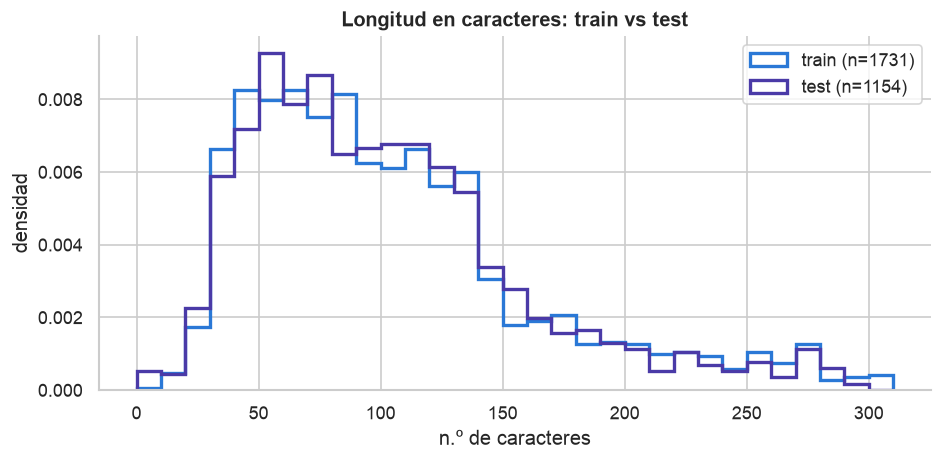

AUC adversarial (recalculado aquí): 0.505 ± 0.022 | longitud mediana: train 91, test 91 | menciones: train 47.5%, test 45.9%


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

show("01_train_vs_test_length.png", 650)
both = pd.concat([texts, test["text"]], ignore_index=True).map(pp.remove_non_ascii)
is_test = np.r_[np.zeros(len(texts)), np.ones(len(test))]
adv = make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True),
                    LogisticRegression(C=1.0, max_iter=2000))
auc = cross_val_score(adv, both, is_test, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")
print(f"AUC adversarial (recalculado aquí): {auc.mean():.3f} ± {auc.std():.3f} | longitud mediana: train {texts.str.len().median():.0f}, "
      f"test {test['text'].str.len().median():.0f} | menciones: train {texts.str.contains('@').mean():.1%}, test {test['text'].str.contains('@').mean():.1%}")

**Interpretación:**
- **AUC adversarial de 0.505 ± 0.022:** un clasificador no distingue el train del test mejor que al azar. Coincide con el 0.504 del notebook 01.
- La distribución de longitudes es prácticamente la misma (mediana de 91 caracteres en los dos), y la tasa de menciones es parecida (47.5% frente a 45.9%).
- **Conclusión:** la validación cruzada sobre el train es una buena estimación del rendimiento en el test.

## 4. Preprocesamiento

**Dónde se aplica.** El preprocesamiento se implementó como un transformador de scikit-learn (`TweetPreprocessor`) que va **dentro de cada modelo**. Así:
- el mismo texto crudo pasa exactamente por los mismos pasos en entrenamiento y en predicción;
- lo que se aprende de los datos (el diccionario de restauración de palabras dañadas) se ajusta solo con el fold de entrenamiento.

**Pasos evaluados** (detalle y código en el notebook **02_preprocesamiento**):

| Paso | Qué hace | Variantes que lo incluyen |
|---|---|---|
| Limpieza de artefactos | Colapsa comillas duplicadas, decodifica entidades HTML y vacía `#¿NOMBRE?` | V1–V4 |
| Borrado de no ASCII | El mismo borrado que sufrió el train (también para textos externos) | V1–V4 |
| Usuarios y enlaces | `@usuario` → `<USER>`, enlace → `<URL>` | V1–V4 |
| Hashtags y RT | `#palabra` → `palabra`; se quita `RT` | V1–V4 |
| Minúsculas | Todo en minúsculas | V1–V4 |
| Alargamientos, risas y censura | *holaaaa* → *holaa* (o *hola* en "alarg.=1"), risas → *jaja*, *p\*ta* → *puta* | V2–V4 |
| Restauración | Palabras dañadas por el borrado de tildes → forma correcta sin tilde (*cllate* → *callate*), con un diccionario propio de 178 entradas | V3–V4 |
| Lemas (spaCy) | Vista adicional con los lemas corregidos | V4 |

V0 es el texto crudo. **No se quitaron stopwords:** palabras como *tú*, *te* o *eres* son señales de TR (3.4).

Ejemplos reales del train con las variantes V1 y V3:

In [10]:
examples = train.loc[[texts.str.contains("@").idxmax(), texts.str.contains("cllate").idxmax(),
                      texts.map(lambda t: bool(re.search(r"(\w)\1{3,}", t))).idxmax(), texts.str.contains("#").idxmax()], "text"]
views = {v: pp.TweetPreprocessor(v).fit(texts).transform(examples)["text"].to_numpy() for v in ("V1", "V3")}
display(pd.DataFrame({"texto crudo": examples.to_numpy(), "V1": views["V1"], "V3": views["V3"]}))

,texto crudo,V1,V3
0,@SomosRedSaime amigos SAIME mi nombre es walter perez V-13.899.989 wperez001@gmail.co...,<USER> amigos saime mi nombre es walter perez v-13.899.989 wperez001@gmail.com y desde...,<USER> amigos saime mi nombre es walter perez v-13.899.989 wperez001@gmail.com y desde...
1,@DaamiWeht @LuViera_Carp La puta madre Damin cllate jajajaja,<USER> <USER> la puta madre damin cllate jajajaja,<USER> <USER> la puta madre damin callate jaja
2,@srtaalegre_ Siiii jajjajajajjajajaja yo te iba a ensear pero vivs lejos nde puta.,<USER> siiii jajjajajajjajajaja yo te iba a ensear pero vivs lejos nde puta.,<USER> sii jaja yo te iba a ensenar pero vivs lejos nde puta.
3,#Sudaca Escucha tu #Rock clsico latinoamericano favorito. Sintonzanos a las 8AM por ht...,sudaca escucha tu rock clsico latinoamericano favorito. sintonzanos a las 8am por <URL...,sudaca escucha tu rock clsico latinoamericano favorito. sintonzanos a las 8am por <URL...


### 4.1 Comparación de variantes

**Diseño:** las 6 variantes se compararon con un modelo fijo, para que solo cambiara el preprocesamiento:
- regresión logística balanceada;
- TF-IDF de palabras (1–2 gramas) y de caracteres (`char_wb`, 2–5 gramas);
- umbral 0.5 y los mismos 5 folds.

Cada línea gris de la figura es un fold, así que se ve si la mejora se repite en todos.

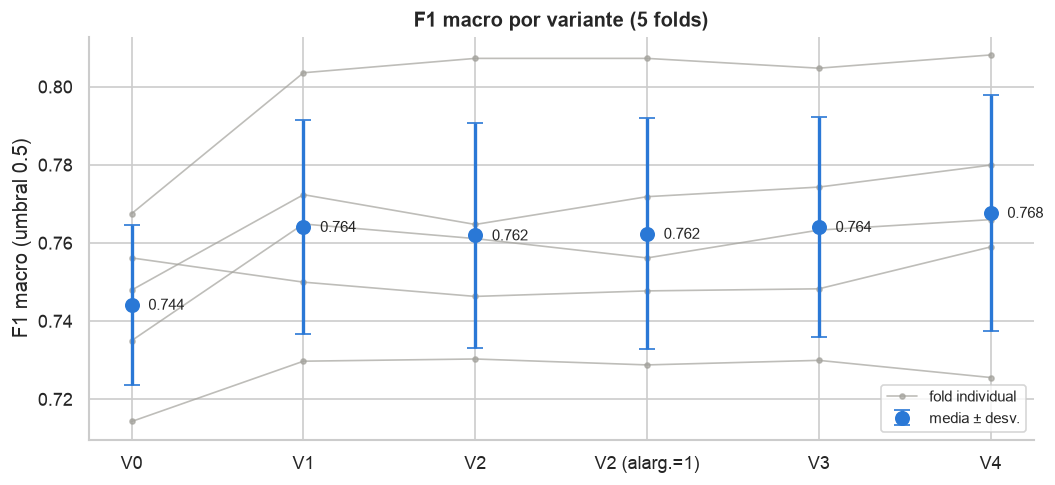

,pasos,F1 HS,F1 TR,F1 AG,F1 macro,desv.
variante,,,,,,
V0,texto crudo,0.741,0.767,0.725,0.744,0.020
V1,limpieza + minúsculas (referencia),0.761,0.800,0.731,0.764,0.027
V2,"V1 + alargamientos a 2, risas, censura",0.759,0.797,0.730,0.762,0.029
V2 (alarg.=1),V2 con alargamientos a 1,0.760,0.796,0.731,0.762,0.030
V3,V2 + restauración de palabras dañadas,0.764,0.797,0.732,0.764,0.028
V4,V3 + lemas (spaCy) como vista extra,0.760,0.803,0.740,0.768,0.030


In [11]:
show("02_variants_f1.png", 800)
display(pd.read_csv(ART / "reports" / "tables" / "variantes_02.csv").set_index("variante"))

**Interpretación:**
- **Solo la limpieza con minúsculas mejora de forma clara:** de V0 a V1, el F1 macro sube de 0.744 a 0.764 (+0.020, mejor en 4 de 5 folds).
- **V2, V3 y V4 quedan a ±0.004 de V1** (V4: 0.768), muy por debajo de la desviación entre folds (≈0.027): no se distinguen del ruido.
- **Criterio de decisión:** con 1731 tuits, una diferencia menor que la variación entre folds no cuenta, y entre opciones empatadas se prefiere la más simple.

### 4.2 Ablación: qué paso aporta

**Diseño:** partiendo de la variante más completa (V4), se quitó un paso cada vez y se midió el cambio emparejado por fold. En azul aparecen los pasos cuya contribución supera la variación entre folds.

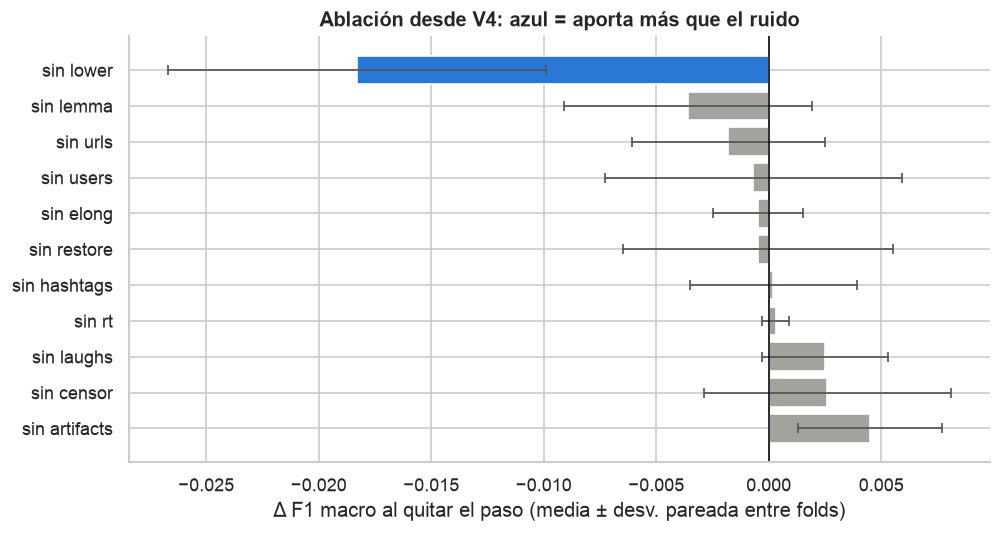

In [12]:
show("02_ablation.png", 760)

**Interpretación y decisiones:**
- **Solo las minúsculas aportan de forma clara:** quitarlas cuesta −0.018 (peor en 5 de 5 folds). Lemas, enlaces, usuarios, alargamientos, restauración, risas y censura quedan dentro de ±0.004.
- **Quitar la limpieza de artefactos *sube* el F1 (+0.004; +0.014 en AG).** Los n-gramas de caracteres aprenden las comillas duplicadas de las filas del artefacto (3.5), que son todas AG=1. Es un atajo del archivo, no lenguaje.
  - **Se decidió mantener la limpieza** y, si se quería explotar el artefacto, hacerlo de forma explícita y declarada. Eso se hizo después con la regla de comillas (8).
- **Otras pruebas del notebook 02:**
  - **vistas del texto:** palabras + caracteres (0.764) superan a solo caracteres (0.741), solo palabras (0.733) y solo lemas (0.729), en 5 de 5 folds. Se adoptó la combinación de palabras y caracteres como representación base;
  - **jerarquía:** forzar TR=0 cuando se predice HS=0 casi no cambia el F1 (+0.0004), pero evita predicciones incoherentes, así que se adoptó. Extenderla a AG empeora (−0.0022) y no se adoptó;
  - **umbral:** el umbral óptimo de cada etiqueta está entre 0.44 y 0.49. Se decidió elegirlo siempre dentro de la validación cruzada, sin mirar el fold evaluado (5).
- **Se conservaron las 6 variantes** en lugar de elegir una sola. Las diferencias entre V1 y V4 estaban dentro del ruido y podían cambiar con otros modelos. De hecho, la restauración (V3) ayudó después a modelos sin n-gramas de caracteres (ExtraTrees +0.014, CNN de caracteres +0.011), y el ensamble final mezcla modelos sobre V1, V2 y V3.

## 5. Validación

**Conceptos:**
- **Validación cruzada (CV) de 5 folds:** el train se parte en 5 trozos. Cada modelo se entrena 5 veces con 4 trozos y se evalúa en el quinto. Cada tuit recibe la predicción de un modelo que **no lo vio**: su predicción *fuera de fold* (**OOF**).
- **Folds estratificados por combinación de etiquetas:** cada fold tiene la misma proporción de 000, 111, 101…
- **Casi duplicados en el mismo fold:** los tuits con el mismo texto normalizado (sin menciones, enlaces ni signos) van juntos. Si no, el modelo vería en entrenamiento la "respuesta" de un tuit de validación.
- **Sin fugas:** todo lo que se aprende de los datos (vocabulario TF-IDF, diccionario de restauración, Word2Vec, hiperparámetros, umbrales) se ajusta **dentro** del fold de entrenamiento.
- **CV anidada:** para elegir hiperparámetros (p. ej. el C de la regresión logística), dentro de cada fold de entrenamiento se hace **otra** CV de 3 folds. El fold externo solo mide.
- **Umbral por etiqueta:** se elige sin mirar el fold evaluado.
  - En los modelos individuales, es el que maximiza el F1 en los otros folds.
  - En los ensambles, es el centro de la meseta de la curva de F1 suavizada (7), menos sensible al ruido que el máximo.
- **`folds_seed2`:** un segundo reparto con otra semilla. **Solo confirma** lo elegido con `folds.csv`; nunca se usa para elegir.
- **Criterio de decisión frente al ruido:** con 1.7k tuits, el F1 varía ≈0.02 entre folds. Un cambio se adopta solo si mejora **≥ +0.005 y en ≥ 4 de 5 folds, en los dos conjuntos de folds**. Las comparaciones son **emparejadas**: el mismo fold con y sin el cambio.

In [13]:
f1s = art.folds["folds"]
groups = texts.map(_near_duplicate_key)
multi = groups[groups.duplicated(keep=False)]
split_groups = sum(len(set(f1s[multi.index[multi == g]])) > 1 for g in multi.unique())
comp = pd.crosstab(f1s, combo, normalize="index").mul(100).round(1)
comp.insert(0, "tuits", np.bincount(f1s))
display(comp)
print(f"Grupos de casi duplicados: {multi.nunique()} ({len(multi)} tuits) | repartidos entre folds distintos: {split_groups}")
assert split_groups == 0
refolds = common.make_folds(train, path=WORK / "folds_recalculados.csv", overwrite=True).to_numpy()
same_partition = (pd.crosstab(refolds, f1s).max(axis=1).sum() == len(train))  # mismos grupos, aunque cambie la numeración
print(f"Folds recalculados aquí con StratifiedGroupKFold (semilla {SEED}, scikit-learn {sklearn.__version__}): "
      f"{'la misma partición que' if same_partition else 'una partición distinta de'} folds.csv. El reparto exacto depende de la "
      "versión de scikit-learn, por eso el proyecto guarda los folds y se usan siempre los guardados.")

col_0,tuits,000,001,100,101,110,111
row_0,,,,,,,
0,347,54.8,1.4,5.5,8.4,1.7,28.2
1,346,54.9,1.4,5.5,8.4,1.4,28.3
2,346,54.9,1.4,5.2,8.4,1.7,28.3
3,346,54.9,1.7,5.2,8.4,1.4,28.3
4,346,54.6,1.4,5.2,8.4,1.7,28.6


Grupos de casi duplicados: 10 (32 tuits) | repartidos entre folds distintos: 0


Folds recalculados aquí con StratifiedGroupKFold (semilla 42, scikit-learn 1.2.2): una partición distinta de folds.csv. El reparto exacto depende de la versión de scikit-learn, por eso el proyecto guarda los folds y se usan siempre los guardados.


**Interpretación:**
- **Folds equilibrados:** cada uno tiene 346–347 tuits y las mismas proporciones de cada combinación (000: 54.6–54.9%; 111: 28.2–28.6%).
- **Casi duplicados:** los 10 grupos (32 tuits) caen enteros en un solo fold, así que ninguno aparece a la vez en entrenamiento y en validación.
- **Reproducibilidad:** con scikit-learn 1.9.1, la versión del proyecto, `StratifiedGroupKFold` reproduce la misma partición. Con otras versiones puede repartir distinto (con 1.2.2 lo hace). Por eso los folds se guardan en `data/processed/` y todas las cifras usan los guardados.

## 6. Diseño experimental y modelos

Los modelos se exploraron en **etapas sucesivas**, de lo más simple a lo más complejo. Cada etapa partió de las conclusiones de la anterior.

| Etapa | Notebook | Qué se hizo | Qué se decidió |
|---|---|---|---|
| 1. Línea base | 03 | 3 clasificadores × 6 variantes, hiperparámetros por defecto | El clasificador importa más que la variante |
| 2. Catálogo clásico | 04 | Cribado de 24 configuraciones (13 clasificadores) en V1 y V3; rasgos hechos a mano; 4 finalistas con CV anidada en las 6 variantes | Mejor familia: regresión logística elasticnet; árboles y boosting, solo por diversidad |
| 3. Redes neuronales | 05 | 5 arquitecturas y embeddings propios; sobreajuste, ajuste, semillas y diversidad | No superan al lineal, pero sus errores son distintos |
| 4. Transformer desde cero | 06 | Tokenización × tamaño, pooling, dropout, aumento de datos, preentrenamiento MLM | No compite (a 0.10 del lineal) |
| 5. Ensamble | 07 | 6 métodos × 4 subconjuntos de modelos, calibración y umbrales | Stacking de 10 modelos (+0.011) |
| 6. Mejoras sin datos externos | 09–10 | Curva de aprendizaje, especialización por etiqueta, 10 semillas, gemelos | Ninguna supera el ruido; la palanca es tener más datos |
| 7. Datos externos | 11 | HatEval deduplicado, 14 modelos reentrenados, 6 candidatos | ≈+0.02 en todos (9) |

**Común a todas las etapas:** los mismos folds, la misma métrica y la decisión por el criterio de 5. Todo se registró en `registry.csv`, y las tablas de esta sección se leen de ese registro.

### 6.1 Etapa 1: línea base (notebook 03)

**Modelos y representación:**

| Clasificador | Hiperparámetros |
|---|---|
| Regresión logística | L2, C = 1, solver liblinear, `class_weight="balanced"` |
| SVM lineal calibrada | C = 1, `class_weight="balanced"`; probabilidades por calibración sigmoide con CV interna de 3 folds |
| Complement Naive Bayes | alpha = 1 |

- **Representación:** TF-IDF de palabras (1–2 gramas, `sublinear_tf`; conserva `<USER>`, `<URL>` y palabras de una letra como *t* o *q*) + TF-IDF de caracteres (`char_wb`, 2–5 gramas, `min_df=2`).
- **Multietiqueta:** un clasificador independiente por etiqueta.
- **Decisión:** umbral por etiqueta elegido en los otros folds y jerarquía HS=0 ⇒ TR=0.

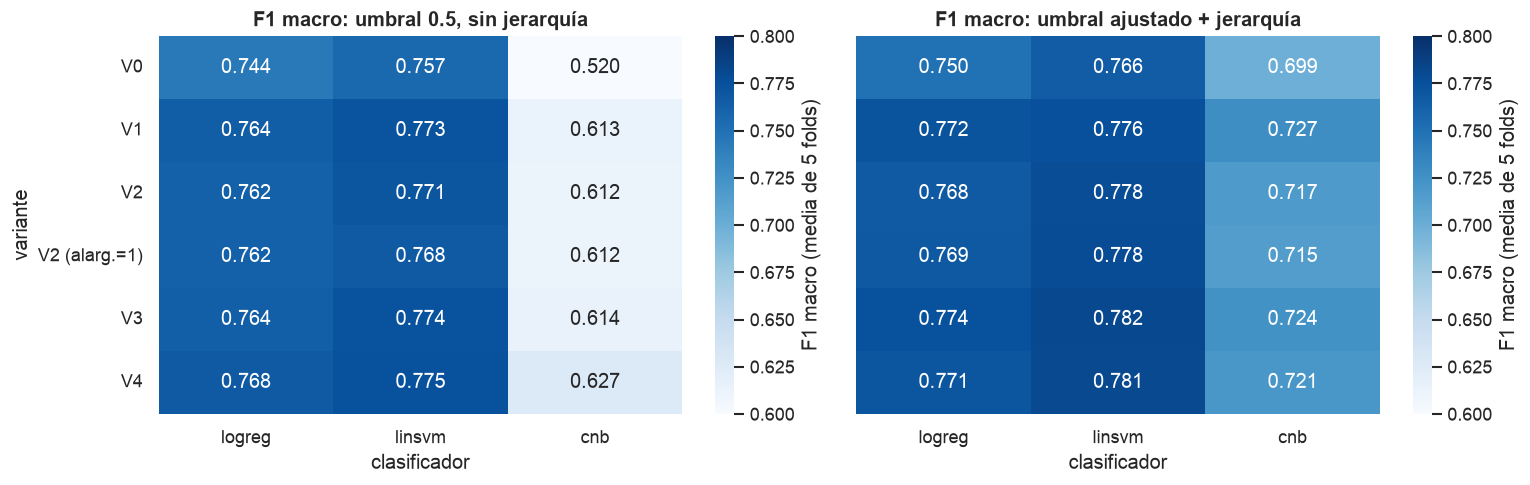

classifier,linsvm,logreg,cnb
variant,,,
V0,0.7663,0.7498,0.6989
V1,0.7756,0.7720,0.7274
V2,0.7776,0.7679,0.7172
V2 (alarg.=1),0.7782,0.7687,0.7153
V3,0.7817,0.7744,0.7244
V4,0.7807,0.7709,0.7210


In [14]:
show("03_f1_heatmap.png", 950)
base = REG[REG["notebook"] == 3]
display(base.pivot_table(index="variant", columns="classifier", values="F1_macro").round(4)
        .reindex(["V0", "V1", "V2", "V2 (alarg.=1)", "V3", "V4"])[["linsvm", "logreg", "cnb"]])

**Interpretación:**
- **El clasificador pesa más que la variante:** la SVM lineal calibrada promedia 0.777 sobre las variantes, la regresión logística 0.767 y Complement NB 0.717.
- **Mejor combinación: V3 + SVM lineal (0.782),** empatada dentro del ruido con la SVM sobre V1, V2 y V4 (0.776–0.781). V0 (texto crudo) es la peor con los tres clasificadores.
- **Ajustar el umbral importa sobre todo en Naive Bayes:** +0.116 de F1, porque sus probabilidades están muy descalibradas (umbrales óptimos de 0.05–0.17). En la SVM aporta +0.008 y en la regresión logística +0.003.
- La jerarquía aporta +0.0016, dentro del ruido; se mantuvo por coherencia.

### 6.2 Etapa 2: catálogo de modelos clásicos (notebook 04)

**Fase A, cribado:** 24 configuraciones con hiperparámetros por defecto, en V1 y V3:

| Familia | Configuraciones (valores por defecto) | Representación |
|---|---|---|
| Lineales | Regresión logística L2, L1 y elasticnet (C = 1); SGD con pérdida logística y *modified Huber* (alpha = 1e-4); SVM lineal (C = 1); NB-SVM (C = 1, alpha = 1) | TF-IDF palabras + caracteres |
| Bayes | Multinomial, Bernoulli y Complement NB (alpha = 1) | TF-IDF de palabras |
| Vecinos y kernel | kNN coseno (k = 15, ponderado por distancia); SVM RBF calibrada (C = 1) | TF-IDF palabras + caracteres |
| Árboles | Random Forest y ExtraTrees (300 árboles, `max_features="sqrt"`, `balanced_subsample`) | Palabras con selección chi² de 500 o 2000 rasgos por etiqueta, o SVD de 300 componentes |
| Boosting | XGBoost (300 árboles, profundidad 4, lr 0.05) y LightGBM (300 árboles, 15 hojas, lr 0.05) | Igual que los árboles |

La selección chi² y la SVD se ajustan dentro de cada fold, como todo lo demás.

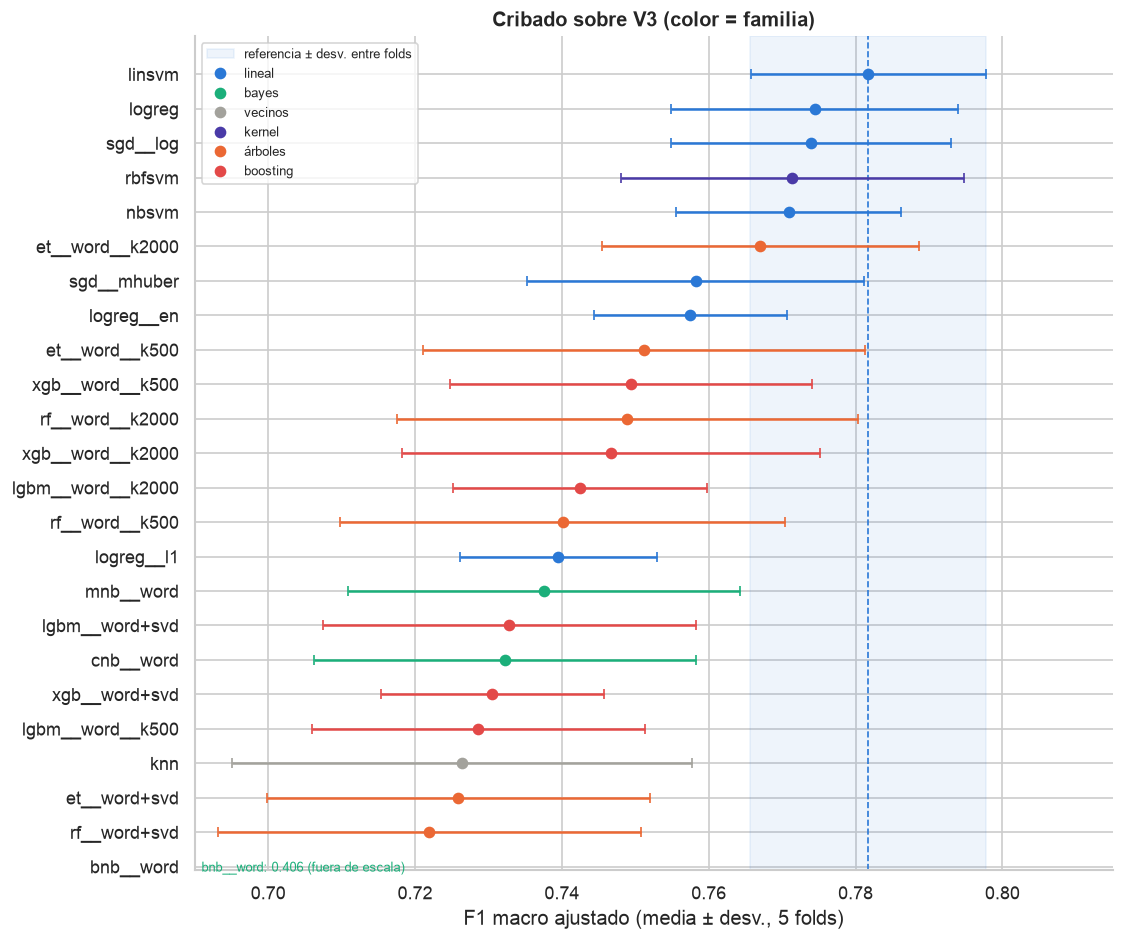

In [15]:
show("04_screening.png", 760)

**Interpretación del cribado (V3):**
- **Ningún modelo supera a la referencia de la etapa 1** (SVM lineal, 0.782; franja azul).
- **Los lineales quedan cerca:** regresión logística L2 (0.774), SGD logística (0.774), NB-SVM (0.771) y SVM RBF (0.771).
- **Árboles y boosting con selección chi²** se quedan entre 0.743 y 0.767; ExtraTrees con 2000 rasgos es el mejor. Con SVD rinden peor (0.722–0.733).
- **Bayes:** Multinomial y Complement NB rondan 0.73–0.74, y **Bernoulli NB colapsa (0.41).** kNN llega a 0.73.
- La regresión logística L1 y la elasticnet con C = 1 rinden mal (0.740 y 0.758): con ese valor de C están demasiado regularizadas, lo que motivó ajustar C en la fase C.

**Fase B, rasgos hechos a mano:** se añadieron 39 rasgos calculados sobre el texto crudo (longitud, menciones, enlaces, mayúsculas, risas, léxicos de insultos, imperativos y segunda persona; `handcrafted.py`). La tabla compara cada modelo con y sin ellos:

In [16]:
hand = REG[(REG["notebook"] == 4) & REG["features"].astype(str).str.contains(r"\+hand")]
rows = []
for mid, r in hand.iterrows():
    base_id = mid.replace("__tfidf+hand", "").replace("+hand", "")
    if base_id in REG.index:
        rows.append({"modelo": base_id, "sin rasgos": REG.loc[base_id, "F1_macro"], "con rasgos": r["F1_macro"],
                     "Δ": round(r["F1_macro"] - REG.loc[base_id, "F1_macro"], 4)})
display(pd.DataFrame(rows).set_index("modelo").sort_values("Δ"))

,sin rasgos,con rasgos,Δ
modelo,,,
V3__logreg,0.7744,0.7674,-0.0070
V3__et__word__k2000,0.7670,0.7605,-0.0065
V1__logreg,0.7720,0.7661,-0.0059
V3__linsvm,0.7817,0.7789,-0.0028
V1__linsvm,0.7756,0.7752,-0.0004
V1__rf__word__k2000,0.7476,0.7480,0.0004
V3__lgbm__word__k2000,0.7425,0.7455,0.0030
V1__et__word__k2000,0.7554,0.7610,0.0056
V3__xgb__word__k500,0.7494,0.7563,0.0069


**Interpretación:**
- **A los lineales no les aportan:** la regresión logística pierde 0.006–0.007 y la SVM lineal 0.000–0.003. El TF-IDF de palabras y caracteres ya contiene esas señales: un imperativo o una mención son n-gramas.
- **Ayudan a la mayoría de árboles y boosting,** que trabajan con pocos rasgos seleccionados por chi²: LightGBM en V1 gana +0.015, XGBoost +0.007/+0.009 y Random Forest hasta +0.007. ExtraTrees es la excepción: gana en V1 (+0.0056) y pierde en V3 (−0.0065).
- **Decisión:** los rasgos hechos a mano no se usaron en los modelos lineales ni en el ensamble final. Quedaron como opción documentada en el notebook 04.

**Fase C, finalistas con CV anidada:** los 4 mejores lineales del cribado se ajustaron en las 6 variantes, eligiendo los hiperparámetros con una CV interna de 3 folds dentro de cada fold externo:

| Clasificador | Rejilla de hiperparámetros |
|---|---|
| Regresión logística | L2 con C ∈ {0.3, 1, 3, 10, 30}; elasticnet (l1_ratio 0.5) con C ∈ {1, 3, 10}; L1 con C ∈ {3, 10} |
| SVM lineal calibrada | C ∈ {0.03, 0.1, 0.3, 1, 3} |
| SGD | pérdida ∈ {logística, *modified Huber*} × alpha ∈ {1e-5, 3e-5, 1e-4, 3e-4} |
| SVM RBF calibrada | C ∈ {0.3, 1, 3, 10} |

Para Bayes, kNN, árboles y boosting también se definieron rejillas (notebook 04), pero no llegaron a finalistas.

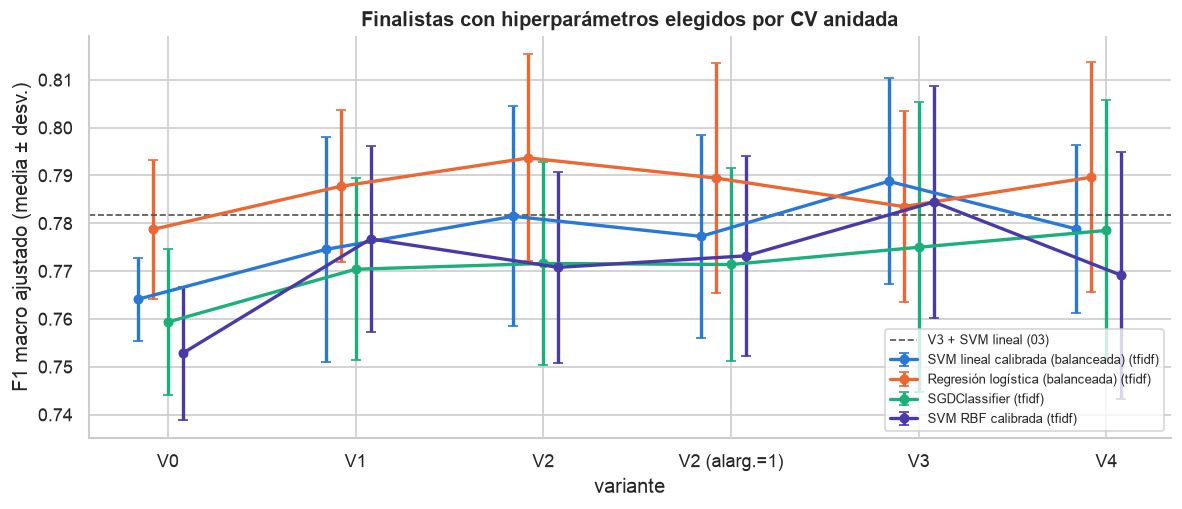

variant,V0,V1,V2,V2 (alarg.=1),V3,V4
classifier,,,,,,
linsvm,0.7641,0.7745,0.7815,0.7773,0.7888,0.7788
logreg,0.7787,0.7877,0.7937,0.7895,0.7835,0.7896
rbfsvm,0.7529,0.7767,0.7708,0.7732,0.7845,0.7691
sgd,0.7594,0.7704,0.7716,0.7714,0.7750,0.7785


,classifier,variant,hiperparámetros elegidos (todo el train),F1_macro,segundos de CV,MB
model_id,,,,,,
V2__logreg__nested,logreg,V2,"{""C"": 10.0, ""l1_ratio"": 0.5}",0.7937,48.0,0.52
V4__logreg__nested,logreg,V4,"{""C"": 10.0, ""l1_ratio"": 0.5}",0.7896,65.3,0.74
V2-alarg1__logreg__nested,logreg,V2 (alarg.=1),"{""C"": 10.0, ""l1_ratio"": 0.5}",0.7895,47.4,0.52
V3__linsvm__nested,linsvm,V3,"{""C"": 1.0}",0.7888,4.2,2.05


In [17]:
show("04_finalists_nested.png", 900)
nested = REG[(REG["notebook"] == 4) & REG.index.str.endswith("__nested")]
tab = nested.pivot_table(index="classifier", columns="variant", values="F1_macro").round(4)
display(tab[["V0", "V1", "V2", "V2 (alarg.=1)", "V3", "V4"]])
best = nested.sort_values("F1_macro", ascending=False).head(4)[["classifier", "variant", "params", "F1_macro", "cv_seconds", "size_mb"]]
display(best.rename(columns={"params": "hiperparámetros elegidos (todo el train)", "cv_seconds": "segundos de CV", "size_mb": "MB"}))

**Interpretación:**
- **La mejor familia es la regresión logística elasticnet con C entre 3 y 10:** V2 alcanza 0.7937, +0.012 sobre la referencia de la etapa 1 en 5 de 5 folds. V1 llega a 0.7877.
- **La SVM lineal ajustada en V3 (0.7888) y la SVM RBF (0.7845) empatan dentro del ruido.** La RBF cuesta ≈100 s por CV anidada y ocupa 18 MB, frente a ≈4 s y 2 MB de la lineal.
- **Optimismo de la selección:** en `folds_seed2`, la ventaja de la logística ajustada baja de 0.794 a 0.786 y empata con la SVM sin ajustar. Parte de la mejora de la CV anidada era suerte del reparto. Por eso todo lo que se adopta después se confirma también con `folds_seed2`.

**Fase D, diversidad:** para combinar modelos no basta con que sean buenos; deben equivocarse en tuits distintos.
- A la izquierda, la correlación de los errores fuera de fold.
- A la derecha, el % de tuits que el modelo de la fila acierta (las 3 etiquetas) y el de la columna falla.

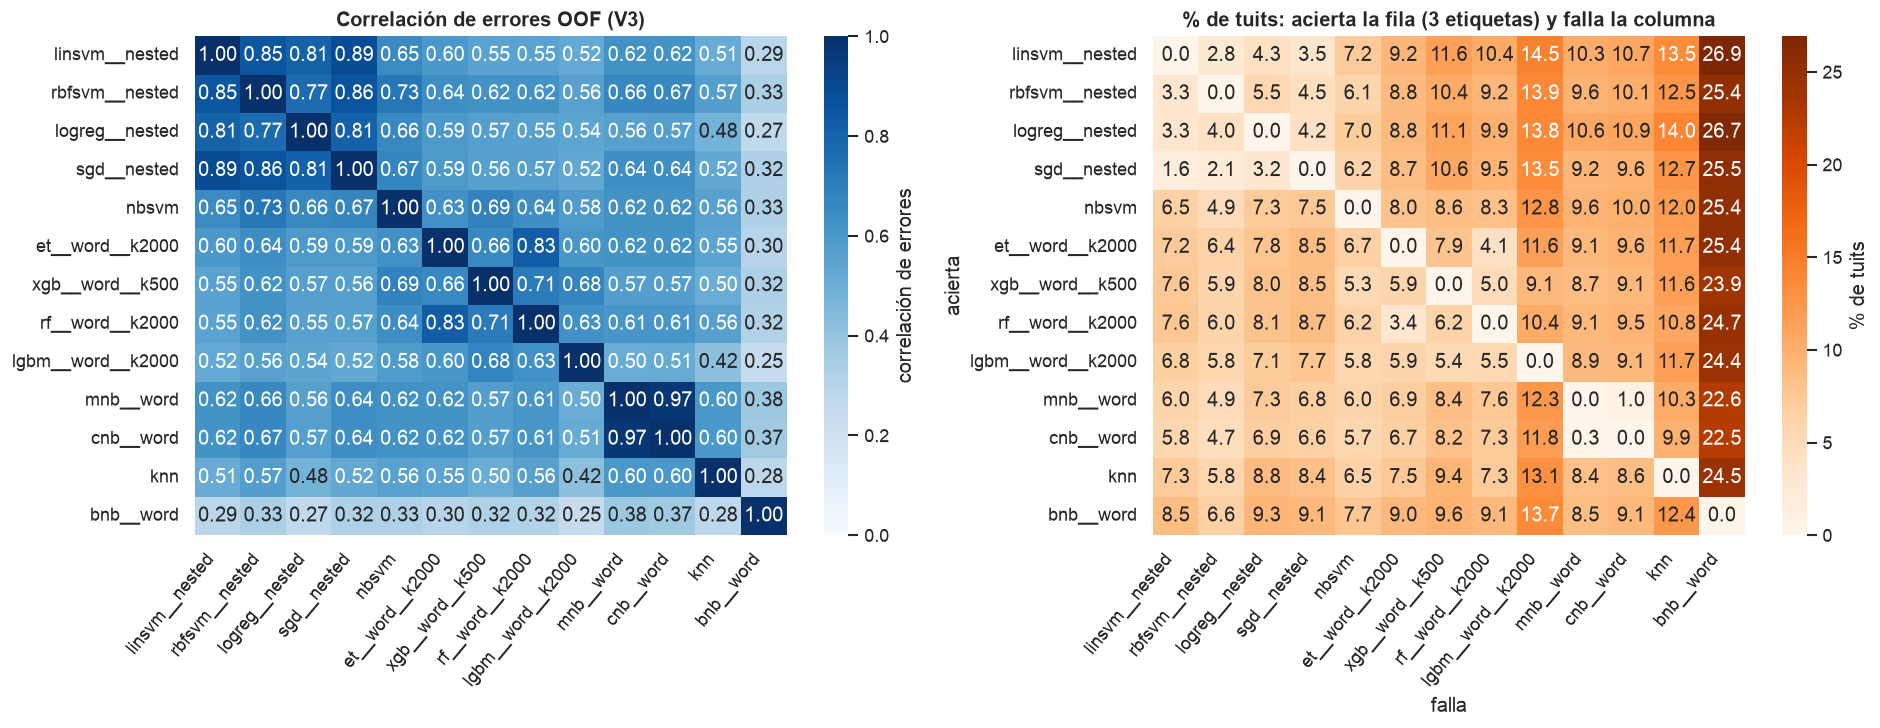

In [18]:
show("04_error_diversity.png", 1000)

**Interpretación:**
- **Los lineales ajustados se equivocan casi igual** (correlación de errores de 0.77 a 0.89): combinarlos aportaría poco.
- **Árboles y boosting tienen correlaciones de 0.52–0.64 con los lineales,** y aciertan las 3 etiquetas en el 6.8–7.6% de los tuits que la SVM falla.
- Multinomial y Complement NB son casi el mismo modelo (0.97).
- **Decisión para el ensamble:** un núcleo de 3 lineales (logística V2 y V1, SVM lineal V3) más ExtraTrees, XGBoost, NB-SVM y Multinomial NB como fuentes de diversidad.

### 6.3 Etapa 3: redes neuronales desde cero (notebook 05)

**Arquitecturas** (todas entrenadas desde pesos aleatorios con el texto del fold):

| Arquitectura | Entrada | Hiperparámetros base |
|---|---|---|
| MLP | TF-IDF palabras + caracteres | 1 capa oculta de 128, dropout 0.5 |
| Estilo fastText | Palabras + n-gramas de caracteres en 20 000 cubetas | Embedding de 100, dropout 0.3, lr 5e-3 |
| CNN de palabras | Secuencia de palabras | Embedding de 100, 64 filtros de ventanas 2, 3 y 4, dropout 0.5 |
| CNN de caracteres | Secuencia de caracteres | Embedding de 32, 64 filtros de ventanas 2, 3 y 4, dropout 0.5 |
| BiGRU con atención | Secuencia de palabras | Embedding de 100, 64 unidades por dirección, dropout 0.4 |

**Entrenamiento común:**
- pérdida BCE con una cabeza de 3 salidas, AdamW (lr 1e-3, *weight decay* 0.01) y lotes de 64;
- hasta 30 épocas con *early stopping* (paciencia 5) sobre una validación interna del 12% del fold de entrenamiento;
- 3 semillas promediadas;
- el modelo final se entrena con todo el train durante la mediana de las mejores épocas de la CV.

**Embeddings propios:** Word2Vec y FastText (gensim, skip-gram, dimensión 100, ventana 5, 30 épocas), entrenados solo con el texto del fold. Se usaron para inicializar las redes de palabras y, promediados, como entrada de una regresión logística.

**Ajuste posterior:** dropout ∈ {0.3, 0.5} × lr ∈ {0.001, 0.002} en la CNN de caracteres y el MLP, y decisiones de diseño: cabezas independientes por etiqueta, ponderar los positivos en la pérdida, e inicializar con Word2Vec o FastText.

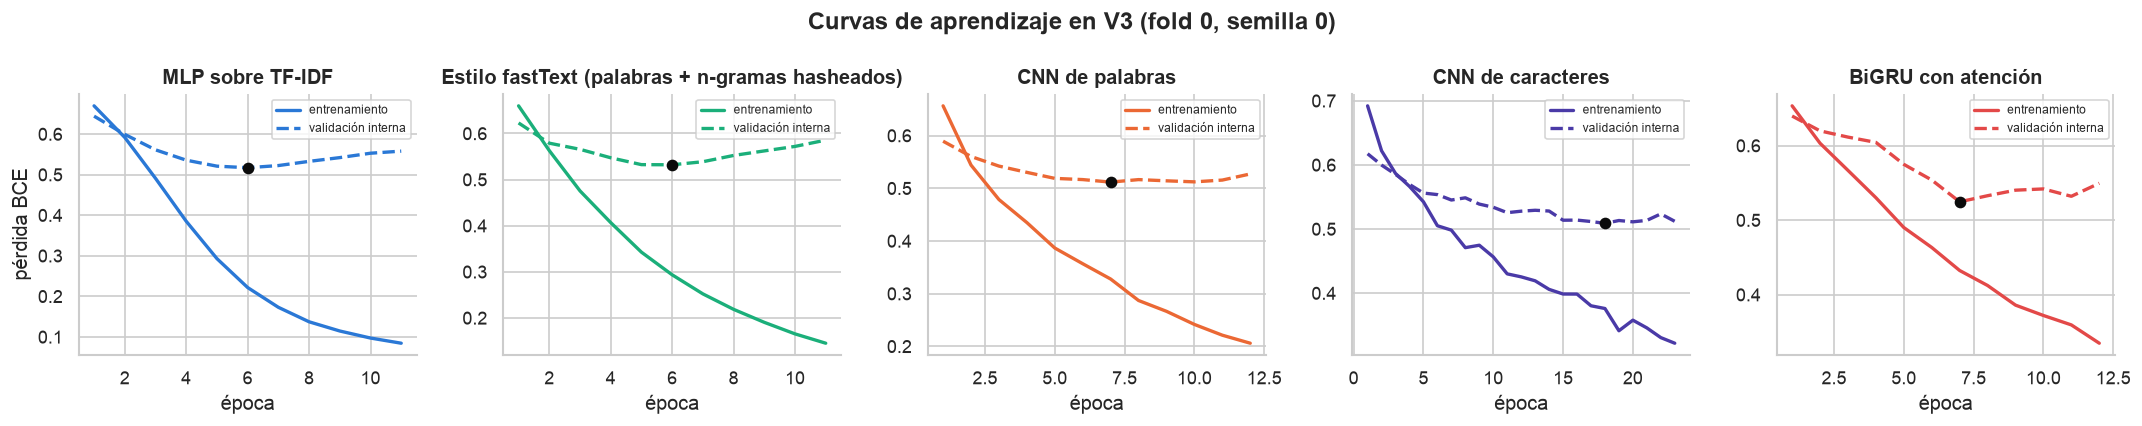

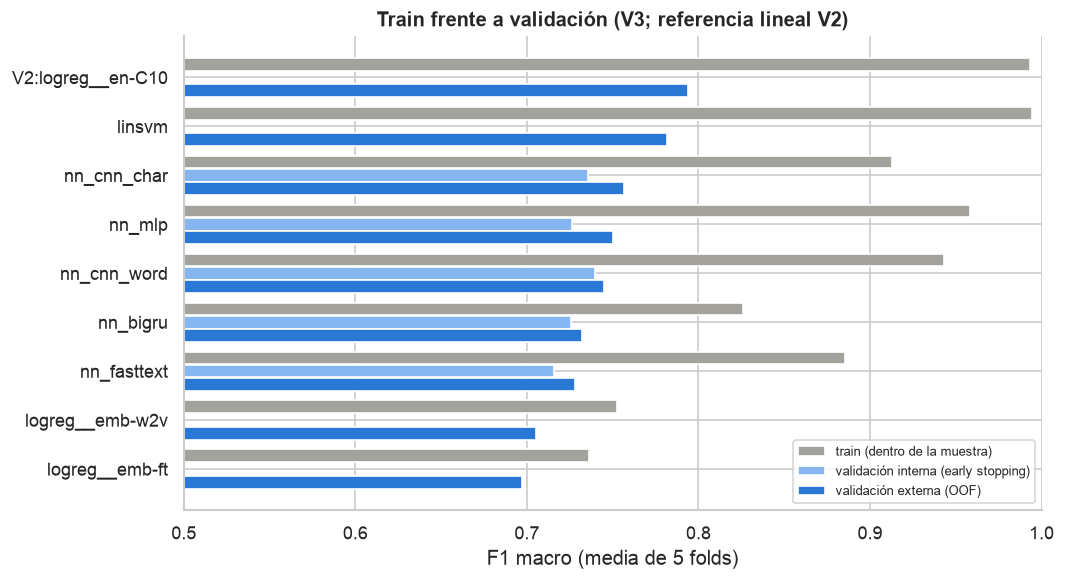

,arquitectura,variant,configuración,F1_macro,segundos de CV,MB
model_id,,,,,,
V1__nn_cnn_char__tune-d0.3-lr0.002,CNN de caracteres,V1,shared|bce|init=random,0.7654,347.6,0.42
V2__nn_cnn_word__w2v,CNN de palabras,V2,shared|bce|init=w2v,0.7644,132.1,3.12
V3__nn_mlp__tune-d0.5-lr0.002,MLP sobre TF-IDF,V3,shared|bce|init=random,0.7550,21.2,67.26
V1__nn_bigru,BiGRU con atención,V1,shared|bce|init=random,0.7330,48.3,3.31
V1__nn_fasttext,Estilo fastText (palabras + n-gramas hasheados),V1,shared|bce|init=random,0.7319,12.7,26.43
V3__logreg__emb-w2v,Regresión logística sobre embeddings propios,V3,emb-w2v,0.7050,1.2,0.79


In [19]:
show("05_learning_curves.png", 1000)
show("05_train_vs_validation.png", 700)
nets = REG[(REG["notebook"] == 5)].copy()
nets["arquitectura"] = nets["classifier"].map(md.CLASSIFIER_NAMES)
nets.loc[nets["features"].astype(str).str.startswith("emb-"), "arquitectura"] = "Regresión logística sobre embeddings propios"
bestnets = nets.sort_values("F1_macro", ascending=False).groupby("arquitectura").head(1)
display(bestnets[["arquitectura", "variant", "features", "F1_macro", "cv_seconds", "size_mb"]]
        .rename(columns={"features": "configuración", "cv_seconds": "segundos de CV", "size_mb": "MB"}))

**Interpretación:**
- **Curvas de aprendizaje:** la pérdida de entrenamiento baja sin parar, mientras que la de validación interna toca fondo entre las épocas 6 y 18 (punto negro) y luego sube. El *early stopping* corta ahí el sobreajuste.
- **Sobreajuste:**
  - las CNN y el MLP aprenden el train casi de memoria (F1 de 0.91–0.96), con una brecha de 0.16–0.21 frente a la validación externa, parecida a la de los lineales;
  - la BiGRU ajusta peor el train (0.82);
  - los embeddings promediados se quedan cortos incluso en el train (0.73–0.75): subajustan;
  - la validación interna no es optimista frente a la externa.
- **Resultados:** la CNN de caracteres (0.7654) y la CNN de palabras con Word2Vec (0.7644) son las mejores, seguidas del MLP (0.7550), la BiGRU (0.7330) y el estilo fastText (0.7319). Los embeddings promediados con regresión logística se quedan en 0.684–0.705.
- **Ninguna red alcanza al mejor lineal (0.794):** con ≈1.4k tuits por fold no hay datos para aprender buenas representaciones.
- **Decisiones de diseño:**
  - la cabeza compartida empata con 3 redes independientes y es 3 veces más barata;
  - ponderar los positivos empeora en 5 de 5 folds (−0.007 a −0.012);
  - inicializar la CNN de palabras con Word2Vec propio aporta +0.011 y reduce la variación entre semillas;
  - promediar 3 semillas sube el F1 +0.006 de mediana (hasta +0.027).

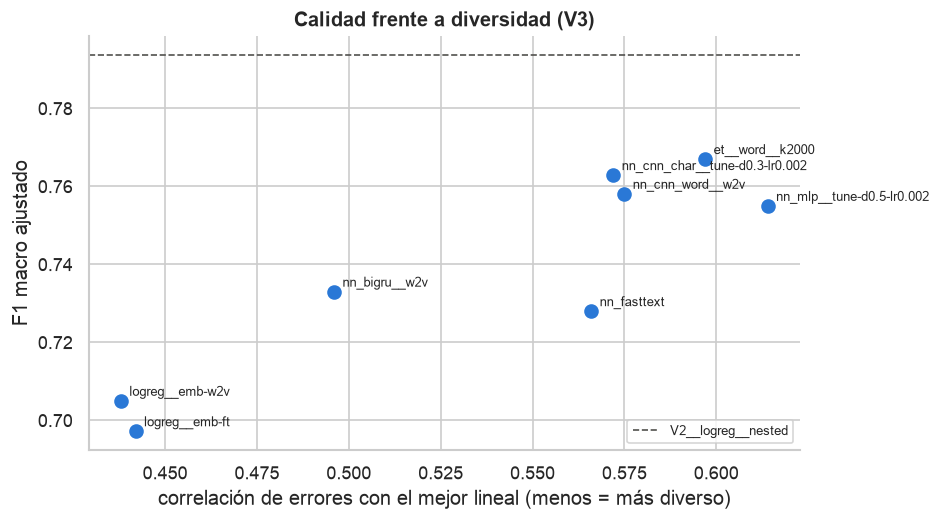

In [20]:
show("05_diversity.png", 650)

**Interpretación:**
- **Las redes son más diversas que buenas:** sus errores se correlacionan 0.50–0.61 con los del mejor lineal (línea discontinua), como ExtraTrees.
- **Las de mejor equilibrio entre calidad y diversidad son** la CNN de caracteres, la CNN de palabras con Word2Vec y el MLP. Se llevaron al ensamble.
- **No se usaron** la BiGRU, el estilo fastText ni los embeddings promediados: son más diversos, pero bastante peores.

### 6.4 Etapa 4: Transformer desde cero (notebook 06)

**Encoder:** pre-LayerNorm, 4 cabezas de atención, pooling por media o por un token [CLS], y un tokenizador **entrenado desde cero** con el texto del fold (caracteres o BPE).

**Entrenamiento:** AdamW (lr 5e-4, *weight decay* 0.02), 10% de *warmup* y decaimiento lineal, lotes de 32, hasta 40 épocas con paciencia 6, y 3 semillas promediadas.

| Fase | Qué se varió |
|---|---|
| 1 | Tokenización {caracteres, BPE de 800, BPE de 2000} × tamaño {d_model 64 con 1 capa, d_model 128 con 2 capas} × variante {V1, V3} |
| 2 | Pooling [CLS], dropout 0.3, aumento de datos (5% de ruido en caracteres y 10% de tokens borrados) |
| 3 | Variantes V0–V3 con la mejor configuración |
| 4 | Preentrenamiento MLM (enmascarar el 15% de los tokens) de 20 y 60 épocas con el texto del fold |

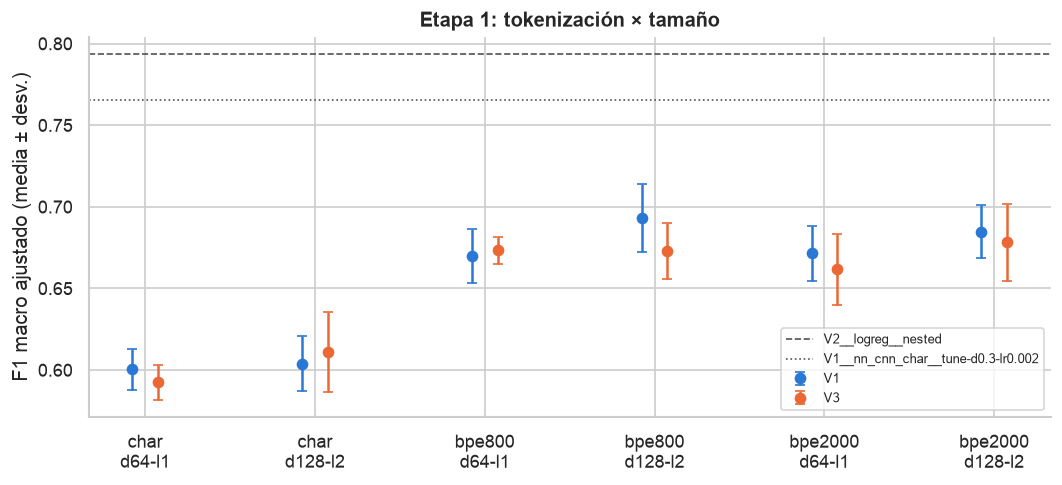

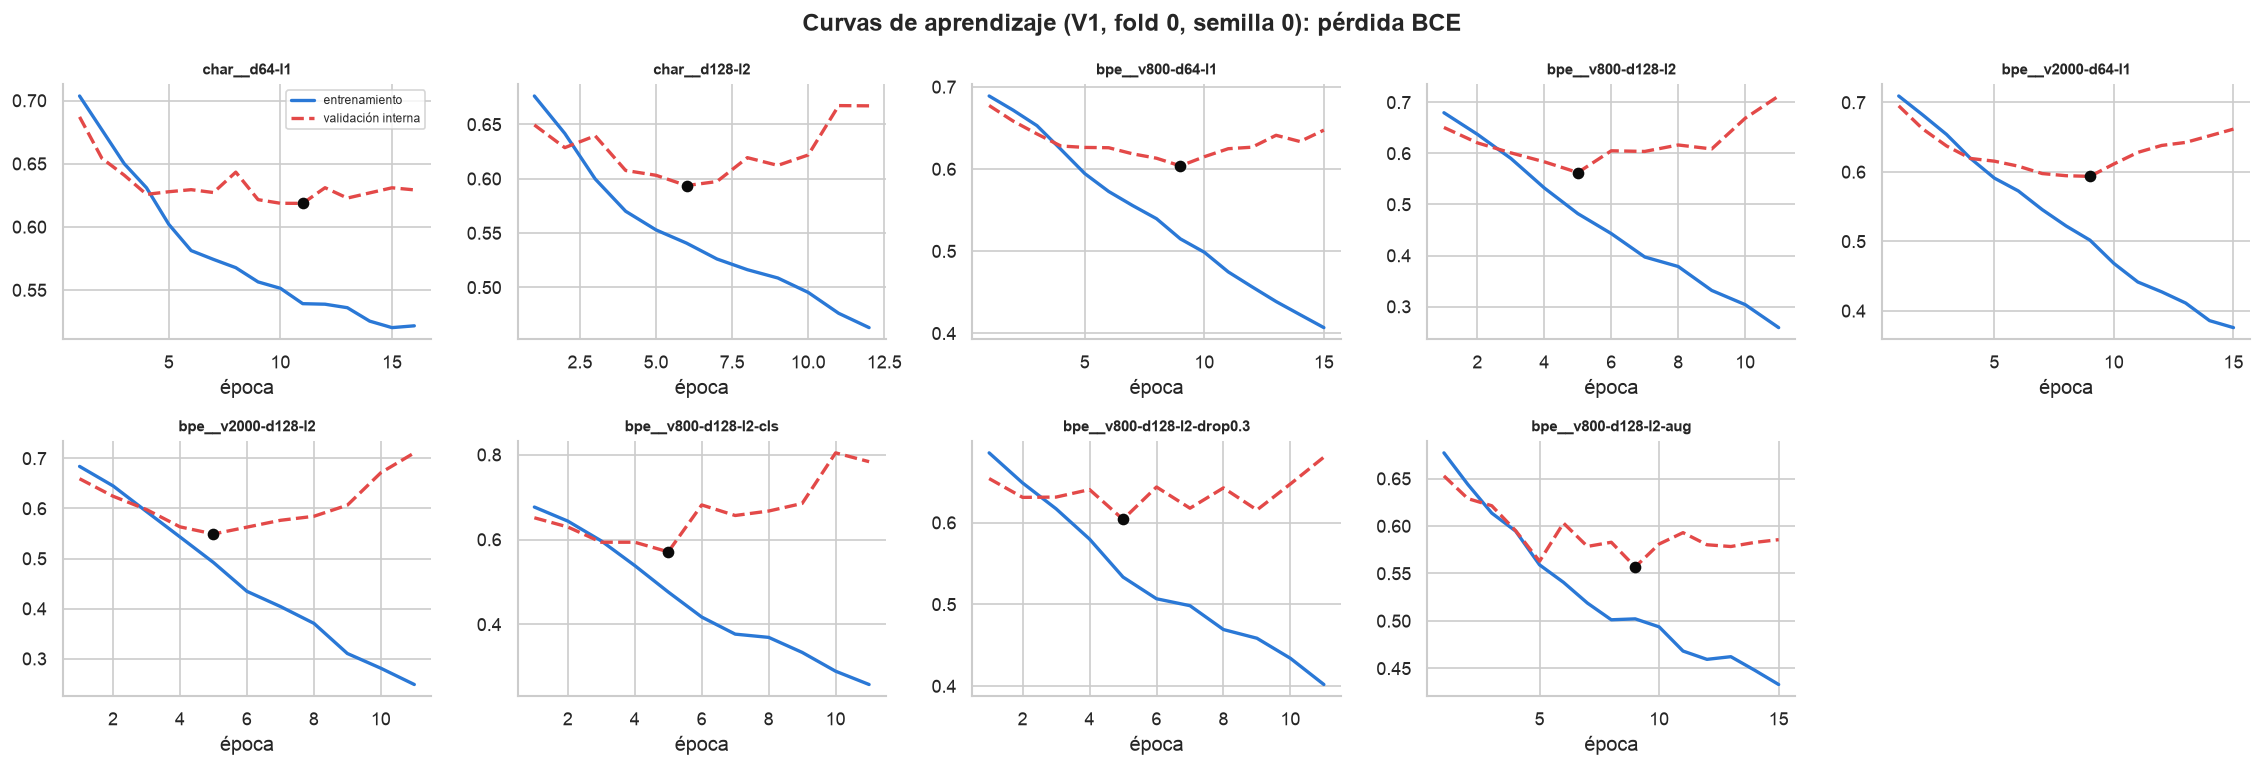

,variant,configuración,F1_macro,segundos de CV
model_id,,,,
V1__nn_trf_bpe__v800-d128-l2-aug,V1,bpe800|d128-l2|mean|drop0.1|aug=True|mlm=0,0.7052,296.6
V1__nn_trf_bpe__v800-d128-l2,V1,bpe800|d128-l2|mean|drop0.1|aug=False|mlm=0,0.6930,162.7
V2__nn_trf_bpe__v800-d128-l2,V2,bpe800|d128-l2|mean|drop0.1|aug=False|mlm=0,0.6922,177.0
V1__nn_trf_bpe__v800-d128-l2-cls,V1,bpe800|d128-l2|cls|drop0.1|aug=False|mlm=0,0.6885,161.9
V1__nn_trf_bpe__v2000-d128-l2,V1,bpe2000|d128-l2|mean|drop0.1|aug=False|mlm=0,0.6848,120.0
V1__nn_trf_bpe__v800-d128-l2-drop0.3,V1,bpe800|d128-l2|mean|drop0.3|aug=False|mlm=0,0.6790,213.9
V3__nn_trf_bpe__v2000-d128-l2,V3,bpe2000|d128-l2|mean|drop0.1|aug=False|mlm=0,0.6782,122.0
V1__nn_trf_bpe__v800-d128-l2-mlm20,V1,bpe800|d128-l2|mean|drop0.1|aug=False|mlm=20,0.6763,513.3


In [21]:
show("06_stage1.png", 760)
show("06_learning_curves.png", 1000)
trf = REG[REG["notebook"] == 6].sort_values("F1_macro", ascending=False)
display(trf[["variant", "features", "F1_macro", "cv_seconds"]].head(8)
        .rename(columns={"features": "configuración", "cv_seconds": "segundos de CV"}))

**Interpretación:**
- **La tokenización decide:** con BPE propio se alcanzan 0.662–0.693, frente a 0.593–0.611 con caracteres. El Transformer de caracteres ni siquiera ajusta bien el train.
- **El tamaño, el vocabulario y el pooling empatan.** El dropout 0.3 empeora (−0.014). El aumento de datos da la mejor cifra (0.7052), pero empata con la configuración base dentro del ruido.
- **El preentrenamiento MLM con el texto del fold no ayuda** (−0.017 con 20 épocas y −0.025 con 60): con ≈1.4k tuits no hay texto suficiente para aprender el idioma, y multiplica el coste por 3–8.
- **Las curvas de validación tocan fondo pronto (épocas 5–11)** y suben después: es un modelo de mucha varianza, con 0.653–0.657 por semilla y 0.693 al promediar 3.
- **No entró en el ensamble:** queda a 0.10 del mejor lineal. Sus errores son los menos correlacionados del proyecto (0.45), pero acierta pocos tuits que el lineal falla y falla muchos que acierta.
  - Con más datos (9) subió +0.050, pero siguió por debajo.

### 6.5 Mejor modelo de cada familia

Se recalcularon desde sus predicciones OOF guardadas, con el protocolo del ensamble (7) y en los dos conjuntos de folds. La celda comprueba con `assert` que coinciden con el registro del proyecto (tolerancia 1e-4).

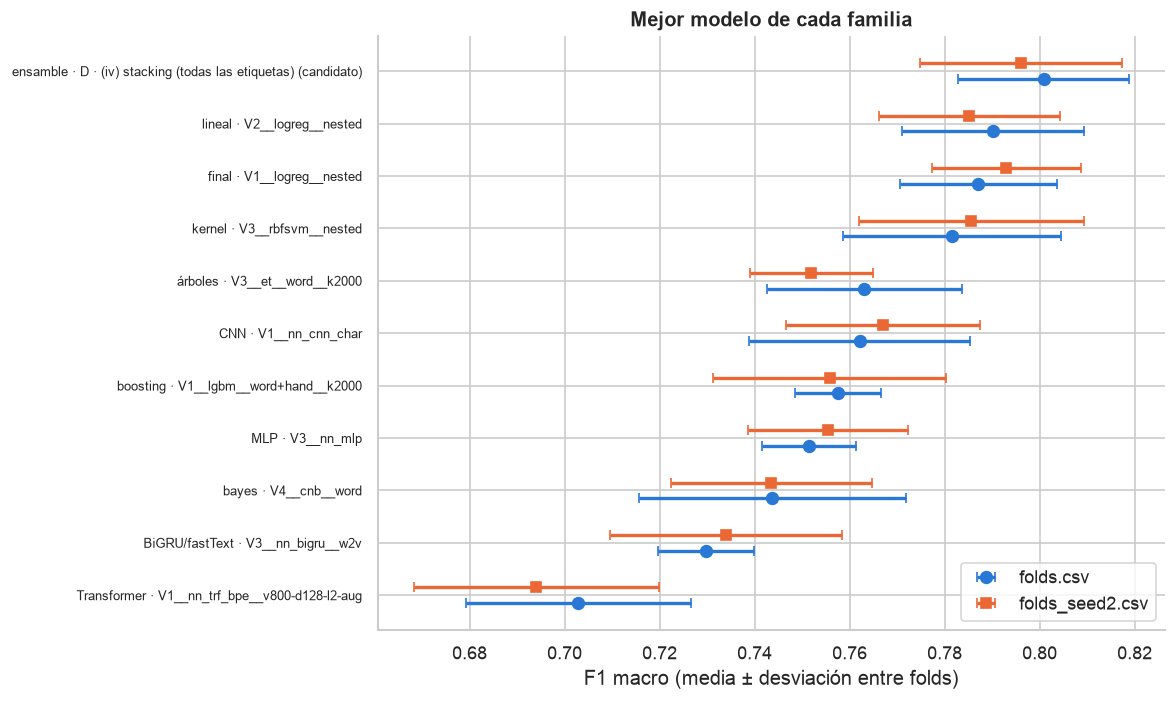

,modelo,F1 HS,F1 TR,F1 AG,F1 macro,F1 macro folds_seed2,registro (su protocolo)
familia,,,,,,,
lineal,V2__logreg__nested,0.781,0.832,0.758,0.7902,0.7852,0.7937
kernel,V3__rbfsvm__nested,0.787,0.812,0.746,0.7815,0.7856,0.7845
árboles,V3__et__word__k2000,0.760,0.810,0.720,0.7631,0.7519,0.7670
CNN,V1__nn_cnn_char__tune-d0.3-lr0.002,0.761,0.793,0.732,0.7621,0.7670,0.7654
boosting,V1__lgbm__word+hand__k2000,0.743,0.805,0.725,0.7575,0.7558,0.7571
MLP,V3__nn_mlp__tune-d0.5-lr0.002,0.758,0.773,0.724,0.7515,0.7554,0.7550
bayes,V4__cnb__word,0.743,0.784,0.703,0.7437,0.7435,0.7461
BiGRU/fastText,V3__nn_bigru__w2v,0.713,0.785,0.691,0.7298,0.7340,0.7330
Transformer,V1__nn_trf_bpe__v800-d128-l2-aug,0.699,0.735,0.675,0.7029,0.6940,0.7052


9 familias: F1 recalculado = registro (1e-4) y = tabla maestra (1e-4) en los dos conjuntos de folds


In [22]:
show("07_families.png", 800)
master = pd.read_csv(ART / "reports" / "tables" / "resultados_finales.csv")
master = master[~master["familia"].isin(["ensamble", "final"])]
rows = []
for _, r in master.iterrows():
    m = r["modelo"]
    s1 = ks.crossfit_rule(art, [m], "single", Y, "folds", rule=False)[1].mean()
    s2 = ks.crossfit_rule(art, [m], "single", Y, "folds_seed2", rule=False)[1].mean()
    regp = ks.f1_registry_protocol(art, m, Y)["F1_macro"]
    assert abs(regp - REG.loc[m, "F1_macro"]) <= 1e-4, (m, regp)
    assert abs(s1["F1_macro"] - r["F1 macro"]) <= 1e-4 and abs(s2["F1_macro"] - r["F1 macro folds_seed2"]) <= 1e-4, m
    rows.append({"familia": r["familia"], "modelo": m, "F1 HS": round(s1["F1_HS"], 3), "F1 TR": round(s1["F1_TR"], 3),
                 "F1 AG": round(s1["F1_AG"], 3), "F1 macro": round(s1["F1_macro"], 4),
                 "F1 macro folds_seed2": round(s2["F1_macro"], 4), "registro (su protocolo)": round(regp, 4)})
FAMILIES = pd.DataFrame(rows).set_index("familia").sort_values("F1 macro", ascending=False)
display(FAMILIES)
print(f"{len(FAMILIES)} familias: F1 recalculado = registro (1e-4) y = tabla maestra (1e-4) en los dos conjuntos de folds")

**Interpretación** (`folds.csv` / `folds_seed2`):
- **Lineales (regresión logística elasticnet sobre TF-IDF): la mejor familia**, con 0.7902 / 0.7852. Con 1731 tuits y miles de n-gramas, un modelo lineal regularizado es lo más eficiente.
- **Kernel (SVM RBF):** 0.7815 / 0.7856. Empata con el lineal en `folds_seed2`, pero es más costosa.
- **Árboles (ExtraTrees) y boosting (LightGBM con rasgos hechos a mano):** 0.7631 y 0.7575. Pierden frente a los lineales en texto disperso, pero cometen errores distintos (6.2).
- **Redes:** CNN de caracteres 0.7621 / 0.7670, MLP 0.7515 y BiGRU 0.7298. No superan al lineal porque con ≈1.4k tuits por fold no hay datos para aprender representaciones, pero entran en el ensamble por su diversidad (7).
- **Naive Bayes:** 0.7437. Rápido, pero descalibrado.
- **Transformer desde cero:** 0.7029 / 0.6940, **el peor**. Con HatEval sube a 0.7557 (9).
- **Protocolos:** la columna "registro" usa el protocolo con el que se evaluó cada modelo en su notebook (umbral que maximiza el F1 en los otros folds) y queda a ≤0.004 de la del ensamble (umbral de meseta). Las dos coinciden con lo registrado.
- **`folds_seed2` confirma el orden,** salvo que la SVM RBF empata con el lineal y ExtraTrees baja 0.011.

## 7. Ensamble (notebook 07)

Se decidió combinar modelos distintos que se equivocan en tuits distintos. Si sus errores no están muy correlacionados, combinarlos corrige parte de ellos.

**Conjunto de modelos**: los 10 modelos elegidos en las etapas 2 y 3. Su correlación de errores:

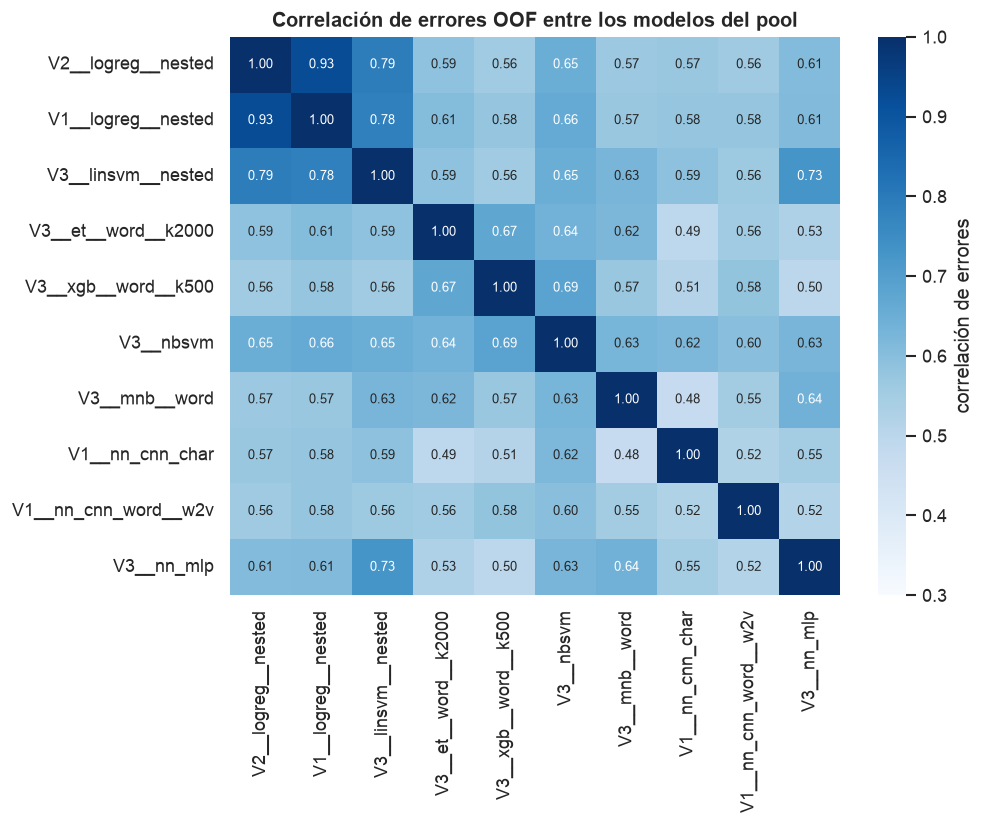

In [23]:
show("07_error_correlation.png", 650)

Los lineales se correlacionan 0.78–0.93 entre sí; las redes, los árboles y Bayes, 0.48–0.73 con ellos.

**Calibración.** Las salidas de algunos modelos no son probabilidades fiables: Naive Bayes, por ejemplo, las lleva a 0 o a 1. Se compararon 4 opciones: sin calibrar, **Platt**, isotónica y por cuantiles.
- Platt ajusta una regresión logística de 2 parámetros sobre el logit de la salida, con datos de entrenamiento, para que "0.7" signifique ≈70%.
- La figura muestra, por tramos de probabilidad predicha, la proporción real de positivos. Un modelo calibrado sigue la diagonal.

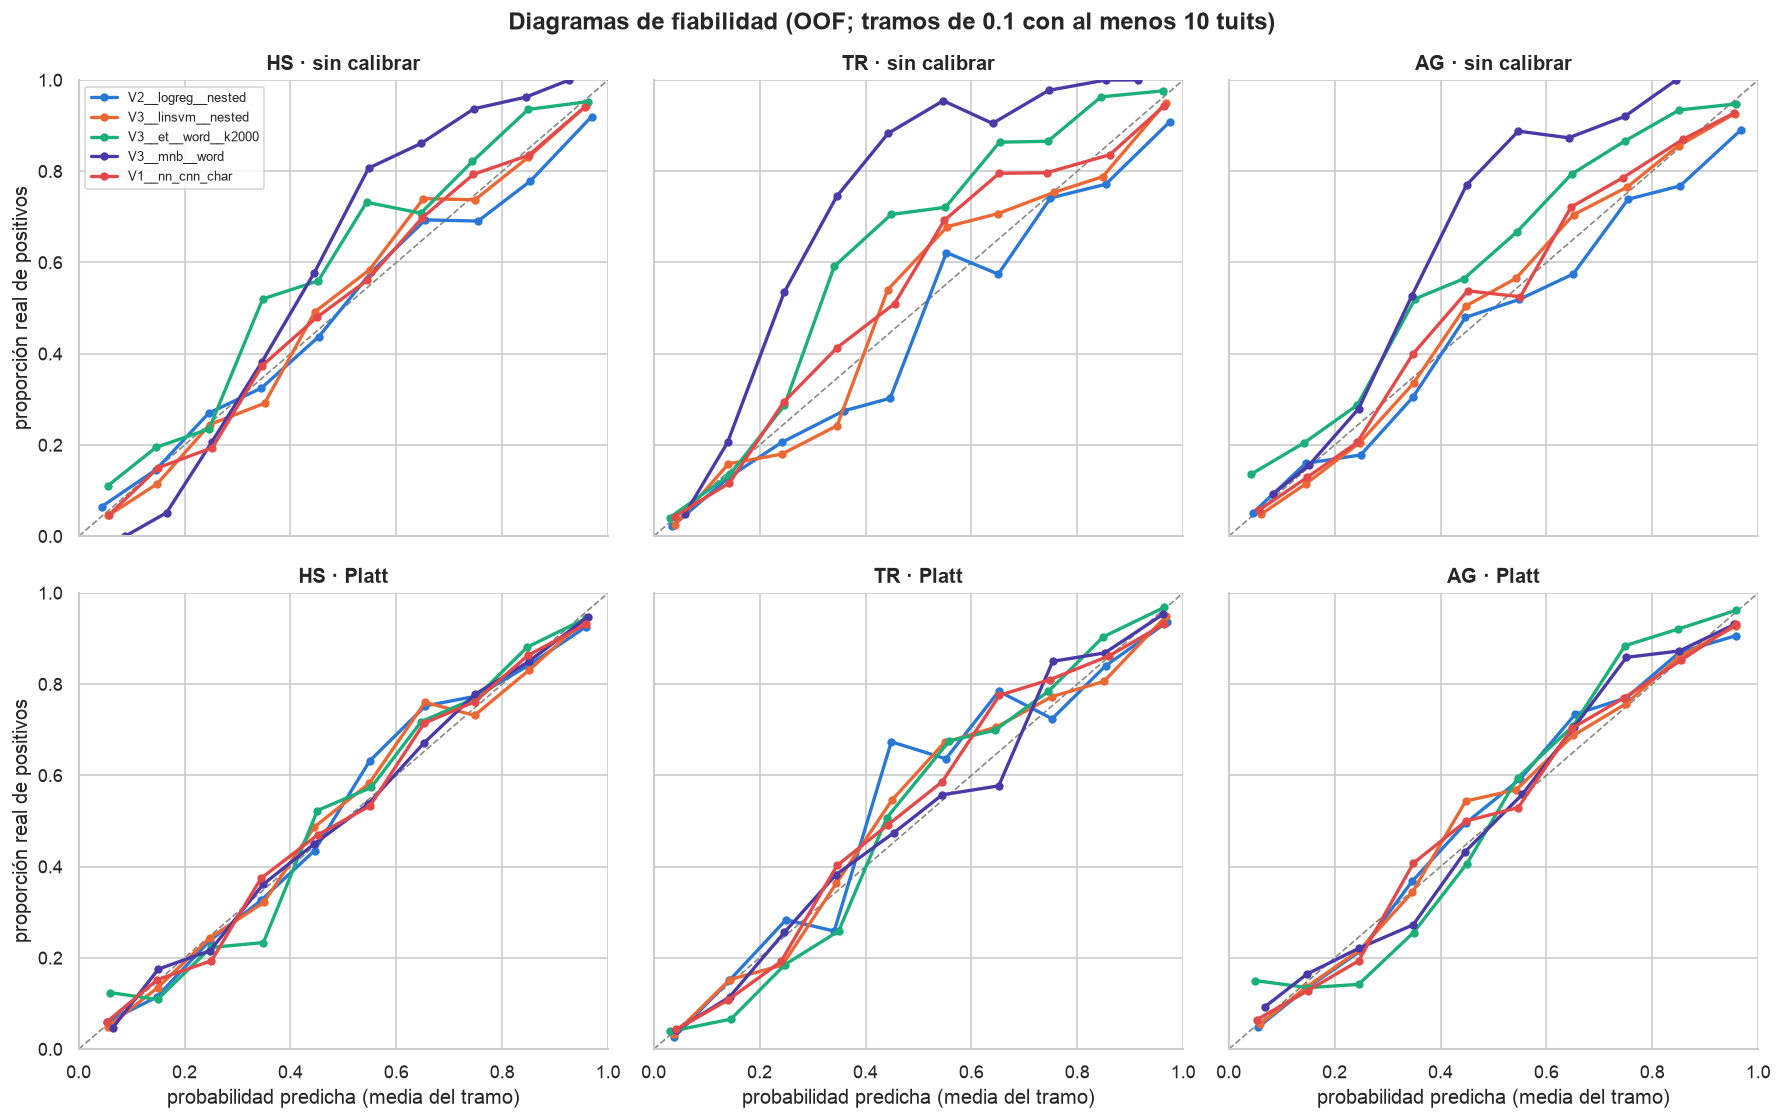

,familia,log-loss sin calibrar,con Platt,mejora
modelo,,,,
V3__mnb__word,bayes,0.4862,0.4290,0.0572
V3__et__word__k2000,árboles,0.4713,0.4458,0.0255
V3__nbsvm,lineal,0.4418,0.4180,0.0238
V1__logreg__nested,lineal,0.3918,0.3819,0.0099
V2__logreg__nested,lineal,0.3933,0.3843,0.0090
V3__xgb__word__k500,boosting,0.4395,0.4352,0.0043
V3__nn_mlp__tune-d0.5-lr0.002,neuronal,0.4232,0.4240,-0.0008
V3__linsvm__nested,lineal,0.3883,0.3896,-0.0013
V1__nn_cnn_word__w2v,neuronal,0.3978,0.3997,-0.0019


In [24]:
show("07_reliability_pool.png", 950)
POOL_D = art.ensembles["FINAL_A_quote"]["base_ids"]
rows = []
f = art.folds["folds"]
for m in POOL_D:
    p = art.oof(m)
    cal = np.zeros_like(p)
    for k in np.unique(f):
        cal[f == k] = en.CalibratedSet("platt").fit(p[f != k][:, None, :], Y[f != k]).transform(p[f == k][:, None, :])[:, 0, :]
    rows.append({"modelo": m, "familia": REG.loc[m, "family"],
                 "log-loss sin calibrar": round(np.mean([en.log_loss(Y[:, j], p[:, j]) for j in range(3)]), 4),
                 "con Platt": round(np.mean([en.log_loss(Y[:, j], cal[:, j]) for j in range(3)]), 4)})
calib = pd.DataFrame(rows).set_index("modelo")
calib["mejora"] = (calib["log-loss sin calibrar"] - calib["con Platt"]).round(4)
display(calib.sort_values("mejora", ascending=False))

**Interpretación:**
- **Antes de calibrar, Naive Bayes y ExtraTrees se alejan mucho de la diagonal:** sus probabilidades son demasiado extremas o mal escaladas. Con Platt, los cinco modelos de la figura siguen la diagonal.
- **En log-loss,** Platt mejora sobre todo a Naive Bayes (−0.057), ExtraTrees (−0.026) y NB-SVM (−0.024). Apenas cambia los lineales y empeora levemente las redes, que ya estaban calibradas.
- **Entre los 4 métodos de calibración,** Platt tuvo la menor log-loss media (0.4119, frente a 0.4242 sin calibrar, 0.4156 isotónica y 0.4876 por cuantiles; notebook 07).
- **Para el F1 con umbral ajustado, calibrar casi no cambia nada.** Sí importa para ponderar o promediar modelos. Por eso los métodos que promedian probabilidades calibran antes, y el stacking trabaja directamente sobre logits.

**Métodos de combinación y subconjuntos.** Se probaron 6 métodos sobre 4 subconjuntos del pool:
- **métodos:**
  1. promedio simple de probabilidades;
  2. promedio de probabilidades calibradas;
  3. pesos ≥ 0 por etiqueta que minimizan la log-loss;
  4. **stacking con todas las etiquetas:** una regresión logística L2 por etiqueta que recibe los logits de las 3 etiquetas de todos los modelos;
  5. selección voraz con reemplazo (Caruana);
  6. stacking solo con la etiqueta propia;
- **subconjuntos:** A = los 3 lineales; B = A + árboles y Bayes; C = A + las 3 redes; D = los 10.

**Protocolo (crossfit):** el combinador también se ajusta dentro de la CV. Para el fold k se ajusta con las OOF de los otros 4 folds, y su umbral sale de una CV interna sobre esos 4.

**Regla de adopción, fijada antes de mirar:** Δ ≥ +0.005 frente al mejor modelo único, y mejor en ≥ 4 de 5 folds, en los dos conjuntos de folds.

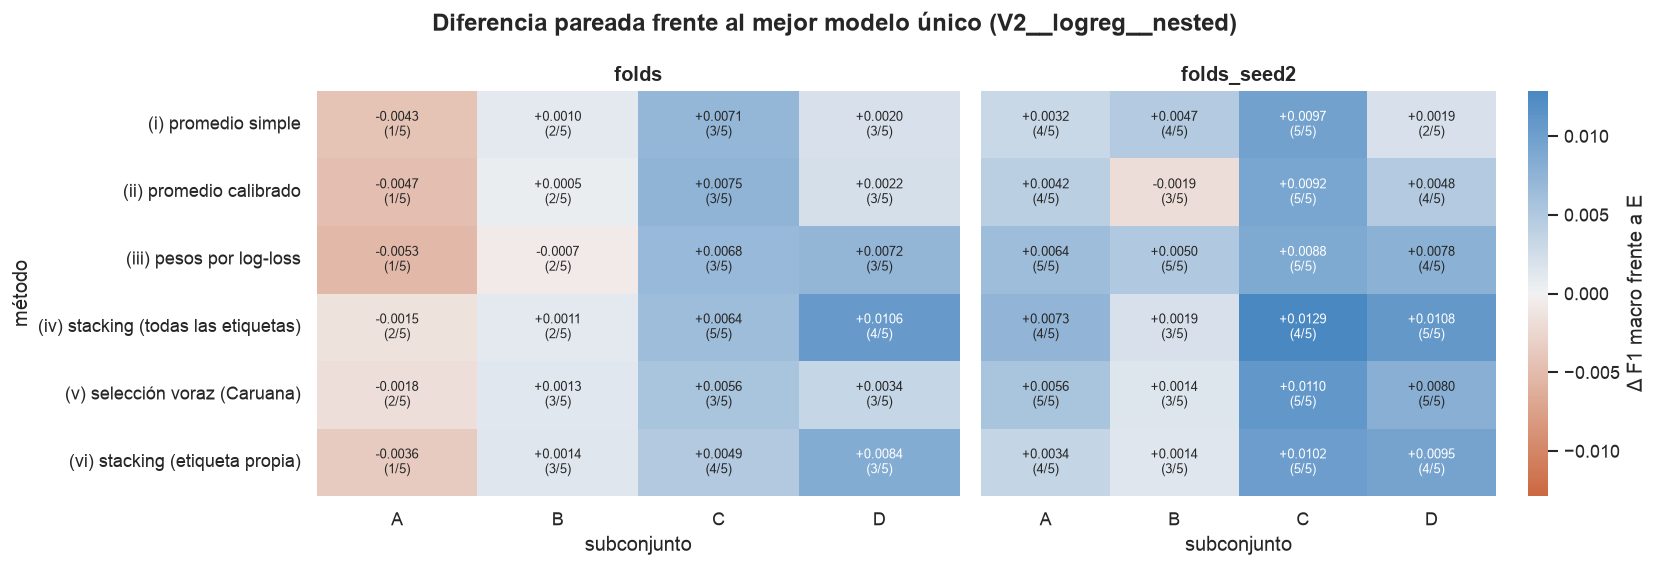

In [25]:
show("07_ensemble_grid.png", 1000)

**Interpretación:**
- **Solo 2 de las 24 combinaciones cumplen la regla en los dos conjuntos de folds:** el stacking con todas las etiquetas sobre C y sobre D. **Se adoptó D** (+0.0106 en 4/5 folds y +0.0108 en 5/5).
- **La diversidad útil la aportan las redes:**
  - A (solo lineales) no gana con ningún método (−0.002 a −0.005);
  - B (lineales + árboles y Bayes) empata;
  - C (lineales + redes) gana con los 6 métodos;
  - quitar las redes del ensamble final cuesta −0.0095, y quitar árboles, boosting o Bayes, ≤ 0.0025 cada uno.
- **El stacking con las 3 etiquetas supera al de la etiqueta propia** (+0.001–0.004 en A, C y D): aprovecha la relación entre HS, TR y AG.

**Umbral de decisión.** El umbral de cada etiqueta se eligió en el **centro de la meseta** de la curva de F1 suavizada, es decir, entre los umbrales cuyo F1 suavizado está a menos de 0.005 del máximo. Es menos sensible al ruido que tomar el máximo exacto (*argmax*).

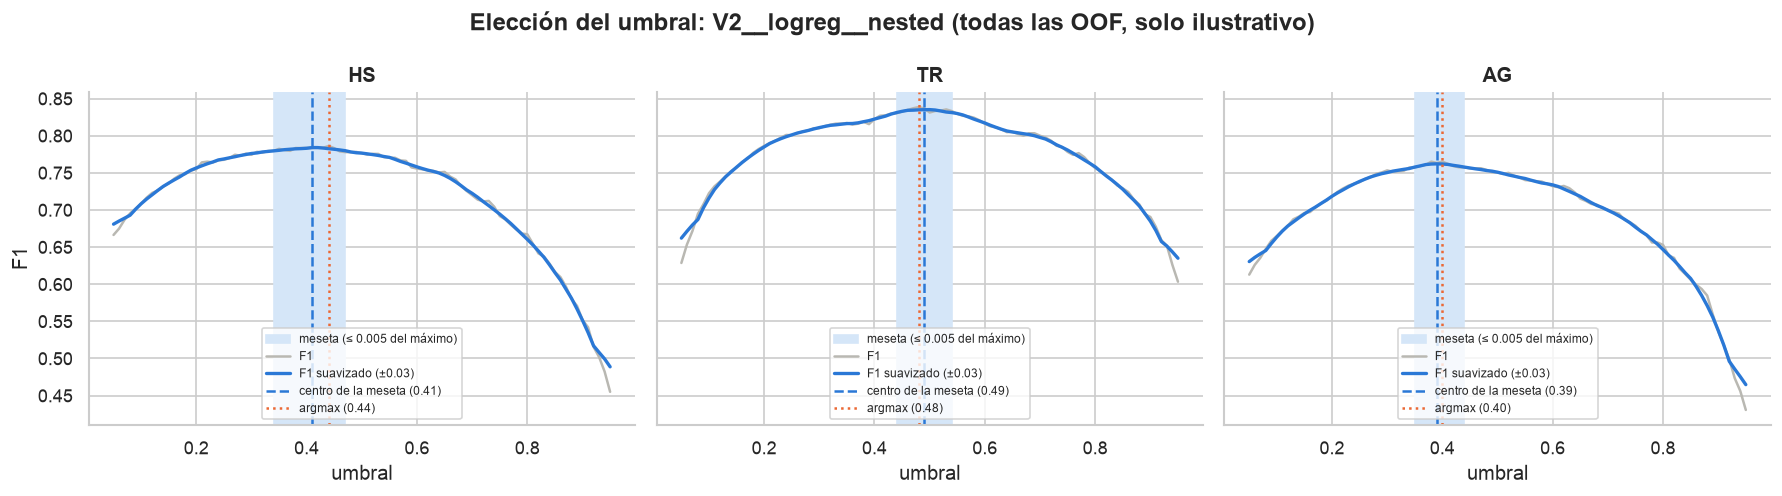

,"mejor modelo único (V2, logística)","FINAL_A (stacking, 10 modelos)",Δ,folds a favor
folds,,,,
folds,0.7902,0.8008,+0.0106 ± 0.0108,4/5
folds_seed2,0.7852,0.7961,+0.0108 ± 0.0065,5/5


Pool del ensamble (10 modelos): V2__logreg__nested, V1__logreg__nested, V3__linsvm__nested, V3__et__word__k2000, V3__xgb__word__k500, V3__nbsvm, V3__mnb__word, V1__nn_cnn_char__tune-d0.3-lr0.002, V1__nn_cnn_word__w2v, V3__nn_mlp__tune-d0.5-lr0.002


In [26]:
show("07_threshold_plateau.png", 950)
best_single = {fs: ks.crossfit_rule(art, ["V2__logreg__nested"], "single", Y, fs, rule=False)[1] for fs in ("folds", "folds_seed2")}
final_a = {fs: ks.cv_from_crossfit(art, "FINAL_A_quote", fs, rule=False) for fs in ("folds", "folds_seed2")}
rows = []
for fs in ("folds", "folds_seed2"):
    d = en.paired_delta(final_a[fs]["F1_macro"], best_single[fs]["F1_macro"])
    rows.append({"folds": fs, "mejor modelo único (V2, logística)": round(best_single[fs]["F1_macro"].mean(), 4),
                 "FINAL_A (stacking, 10 modelos)": round(final_a[fs]["F1_macro"].mean(), 4),
                 "Δ": f"{d['Δ']:+.4f} ± {d['Δ desv.']:.4f}", "folds a favor": f"{d['folds a favor']}/5"})
display(pd.DataFrame(rows).set_index("folds"))
assert abs(final_a["folds"]["F1_macro"].mean() - 0.8008) <= 1e-4 and abs(final_a["folds_seed2"]["F1_macro"].mean() - 0.7961) <= 1e-4
print("Pool del ensamble (10 modelos):", ", ".join(POOL_D))

**Interpretación:**
- **El umbral de meseta queda cerca del máximo** (p. ej. 0.41 frente a 0.44 en HS), pero en una zona donde el F1 es estable. Comparado con el máximo exacto, y con o sin jerarquía, el F1 cambia en ±0.004: dentro del ruido.
- **El ensamble mejora de verdad, aunque poco:** FINAL_A (stacking de las 3 etiquetas sobre los 10 modelos) da 0.8008 / 0.7961, frente a 0.7902 / 0.7852 del mejor modelo único.
  - Δ +0.0106 (4/5 folds) y +0.0108 (5/5): **cumple la regla fijada de antemano** y se adoptó como modelo final antes de los datos externos.
  - En el leaderboard público obtuvo 0.78273, frente a 0.77714 de la mejor logística sola.

## 8. La regla del artefacto de comillas (notebook 08)

- En el train, las 51 filas cuyo texto el CSV guarda entre comillas tienen todas AG=1 (3.5);
- Es un efecto del archivo de la competencia, no del lenguaje.

**La regla:** después de los umbrales, AG=1 en los tuits con `;` o `"`; HS y TR no cambian.

**Cómo se validó:**
- En la CV, la ganancia es **por construcción**: en el train esas filas son siempre AG=1;

In [27]:
rows = []
for fs in ("folds", "folds_seed2"):
    with_rule = ks.cv_from_crossfit(art, "FINAL_A_quote", fs)
    d = en.paired_delta(with_rule["F1_macro"], final_a[fs]["F1_macro"])
    rows.append({"folds": fs, "FINAL_A": round(final_a[fs]["F1_macro"].mean(), 4), "FINAL_A_quote": round(with_rule["F1_macro"].mean(), 4),
                 "F1 AG sin / con regla": f"{final_a[fs]['F1_AG'].mean():.4f} / {with_rule['F1_AG'].mean():.4f}",
                 "Δ": f"{d['Δ']:+.4f} ({d['folds a favor']}/5)"})
display(pd.DataFrame(rows).set_index("folds"))
E = art.ensembles["FINAL_A_quote"]
P_te = np.stack([art.test_proba(m) for m in E["base_ids"]], axis=1)
no_rule = en.decide_from_dict(dict(E, quote_rule=False), P_te, test["text"])
rule = en.decide_from_dict(E, P_te, test["text"])
changed = (no_rule != rule).any(axis=1)
print(f"Test: {QUOTED_TE.sum()} tuits con comillas; la regla cambia {changed.sum()} (solo AG: {(no_rule != rule)[:, :2].sum() == 0}). "
      f"Leaderboard público: FINAL_A 0.78273 → FINAL_A_quote 0.78598 (Δ +0.00325)")

,FINAL_A,FINAL_A_quote,F1 AG sin / con regla,Δ
folds,,,,
folds,0.8008,0.8060,0.7735 / 0.7892,+0.0052 (5/5)
folds_seed2,0.7961,0.8019,0.7613 / 0.7789,+0.0059 (5/5)


Test: 34 tuits con comillas; la regla cambia 5 (solo AG: True). Leaderboard público: FINAL_A 0.78273 → FINAL_A_quote 0.78598 (Δ +0.00325)


**Interpretación:**
- **En la CV**, la regla sube AG de 0.7735 a 0.7892 y el F1 macro +0.0052 (5/5) en `folds.csv` y +0.0059 (5/5) en `folds_seed2`. Es una ganancia por construcción.

## 9. Más datos: HatEval

### 9.1 Mejorar curva de aprendizaje (notebook 09)

**Mejoras probadas sin datos externos que no superaron el ruido** (notebooks 09 y 10; no se usaron):
- **entrenar AG sin las 51 filas del artefacto:** −0.0015 en el lineal; solo mejora 1 de 3 modelos;
- **especializar por etiqueta:**
  - configuración propia por etiqueta (CV anidada entre 10 configuraciones): −0.0023;
  - modelo condicional TR|HS y AG|HS: −0.0083, porque pierde datos;
  - *label powerset* (un clasificador sobre las combinaciones de etiquetas): −0.0107;
- **10 semillas en las CNN:** +0.0099 en la CNN de caracteres sola, pero solo +0.0014 en el ensamble;
- **copiar la etiqueta de los gemelos del train** (21 tuits del test): empeora la CV (−0.0010), y el ensamble ya coincidía con ellos;
- **ampliar el ensamble a 14 modelos con todo lo anterior:** +0.0011 / +0.0042, por debajo de la regla de adopción;

**La curva de aprendizaje** mide el F1 al entrenar con el 25/50/75/100% de cada fold, siempre sobre el fold de validación completo:
- si la curva sigue subiendo al 100%, más datos del mismo tipo ayudarían;
- **no se aplana:** extrapolada a ≈3.7k tuits más, el lineal ganaría **+0.033** (rango razonable +0.01 a +0.05), y la CNN de caracteres algo más.

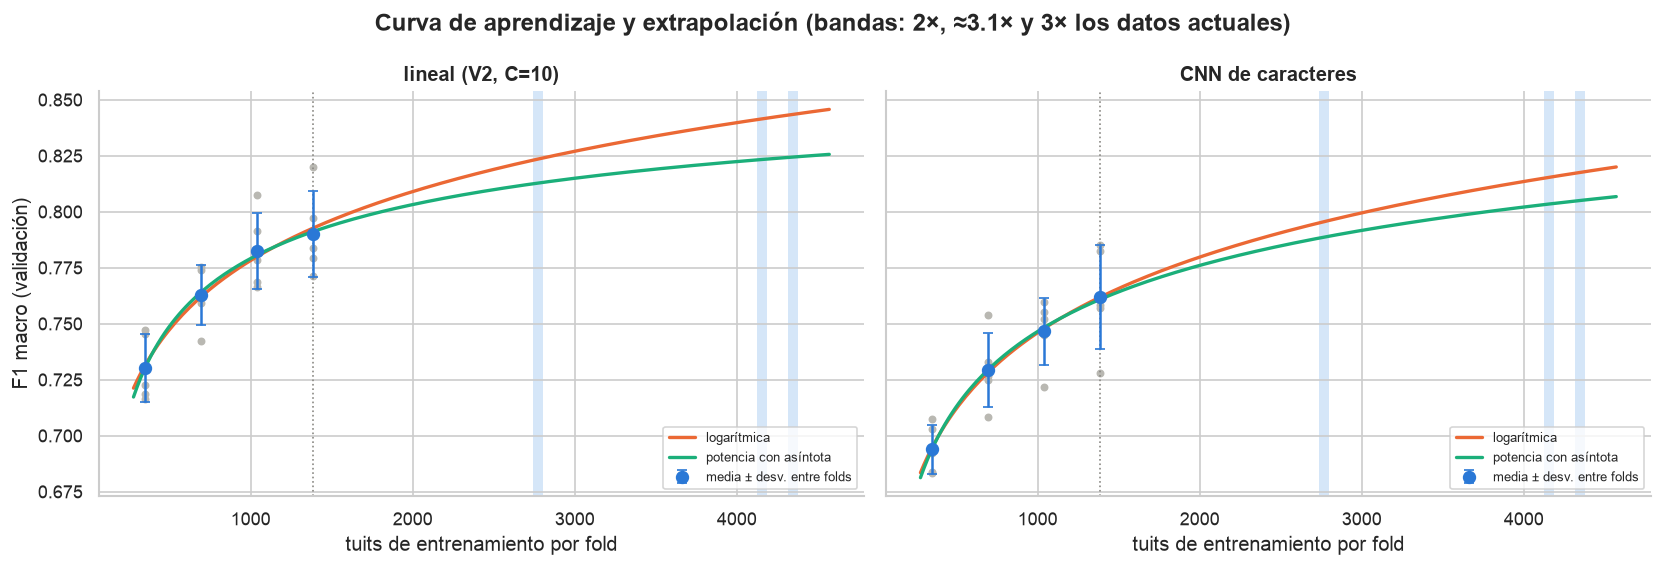

In [28]:
show("09_learning_curve.png", 760)

### 9.2 HatEval y deduplicación estricta (notebook 11)

**Deduplicación** (`external.deduplicate`):
1. **Por id:** se descartan los tuits de HatEval con un id del train o del test.
2. **Por clave normalizada:** mismo texto sin menciones, enlaces, mayúsculas ni signos.
3. **Por similitud coseno ≥ 0.85** de n-gramas de caracteres. El umbral se bajó de 0.9 tras revisar a mano la franja 0.85–0.90, que aún tenía erratas del mismo tuit.
4. **Duplicados internos** de HatEval.

Si un tuit coincide con el train y con el test a la vez, cuenta como del test. **Las etiquetas se leyeron solo después de filtrar**, y nunca las de los tuits que coinciden con el test.

**HatEval no está en el dataset de este notebook.** Solo está su manifest: la revisión fijada y el sha256 de cada archivo.

In [29]:
import json

man = json.loads((ART / "hateval_manifest.json").read_text())
print(f"{man['repo']} @ {man['revision']} | licencia {man['license']} | descargado {man['downloaded']}")
display(pd.DataFrame(man["files"]).T[["rows", "rows_es", "sha256"]].assign(sha256=lambda d: d["sha256"].str[:16] + "…"))
DEDUP = pd.DataFrame([  # resultado de la deduplicación del notebook 11; se recalcula en el modo FULL
    {"resultado": "coinciden con el test de la competencia (descartados sin leer etiquetas)", "por id": 1154, "por clave": 44, "por coseno": 18, "total": 1216},
    {"resultado": "coinciden con el train de la competencia (descartados)", "por id": 1731, "por clave": 11, "por coseno": 15, "total": 1757},
    {"resultado": "duplicados internos", "por id": "—", "por clave": 5, "por coseno": "—", "total": 5},
    {"resultado": "SE CONSERVAN", "por id": "—", "por clave": "—", "por coseno": "—", "total": 3621}]).set_index("resultado")
display(DEDUP)
assert DEDUP["total"].sum() == sum(f["rows_es"] for f in man["files"].values())  # 6599 tuits en español

valeriobasile/HatEval @ d170b5cb1844f3614493fce7c7eaaae087a5201c | licencia cc-by-nc-4.0 | descargado 2026-10-16T01:39:24


,rows,rows_es,sha256
train,13500,4500,60366470d52e6d82…
dev,1500,500,3ad7fcf9b6c89599…
test,4570,1599,c492b18dec54fc9a…


,por id,por clave,por coseno,total
resultado,,,,
coinciden con el test de la competencia (descartados sin leer etiquetas),1154,44,18,1216
coinciden con el train de la competencia (descartados),1731,11,15,1757
duplicados internos,—,5,—,5
SE CONSERVAN,—,—,—,3621


**Compatibilidad:**
- **Mismas etiquetas:** en los tuits con el mismo id, el acuerdo con el train es de 0.9988 en HS y TR, y de 0.9809 en AG. Los desacuerdos en AG son el artefacto de comillas: 31 de 33 tienen comillas.

### 9.3 Protocolo y resultados

**HatEval entra solo en los folds de entrenamiento.** Todo lo que valida usa solo filas de la competencia: las OOF, la CV anidada de hiperparámetros y el *early stopping* de las redes.
- Así, la CV con HatEval es comparable fold a fold con la de antes.
- Cada fila de HatEval pesa 1.0 o 0.5 en la pérdida.

**Cada uno de los 14 modelos del ensamble ampliado**, sin HatEval frente a con HatEval (protocolo del ensamble, sin la regla):

In [30]:
POOL_V2_HE05 = art.ensembles["H5_quote"]["base_ids"]
NO_HE = {"V1__nn_cnn_char__tune-d0.3-lr0.002": "V1__nn_cnn_char__tune-d0.3-lr0.002",
         "V1__nn_cnn_word__w2v": "V1__nn_cnn_word__w2v", "V3__nn_cnn_char__tune-d0.3-lr0.002": "V3__nn_cnn_char__tune-d0.3-lr0.002__s10"}
rows = []
for he05 in POOL_V2_HE05:
    base = he05.rsplit("__he", 1)[0]
    base_id = NO_HE.get(base, base)
    row = {"modelo": base}
    for fs in ("folds", "folds_seed2"):
        b = ks.crossfit_rule(art, [base_id], "single", Y, fs, rule=False)[1]["F1_macro"]
        row[f"sin HatEval [{fs}]"] = round(b.mean(), 4)
        for tag, w in (("05", 0.5), ("10", 1.0)):
            d = en.paired_delta(ks.crossfit_rule(art, [f"{base}__he{tag}"], "single", Y, fs, rule=False)[1]["F1_macro"], b)
            row[f"Δ peso {w} [{fs}]"] = round(d["Δ"], 4)
    rows.append(row)
GAINS = pd.DataFrame(rows).set_index("modelo")
display(GAINS)
dcols = [c for c in GAINS.columns if c.startswith("Δ")]
print("Modelos que mejoran con HatEval:", {c: f"{int((GAINS[c] > 0).sum())}/14" for c in dcols},
      "| Δ medio:", {c: round(GAINS[c].mean(), 4) for c in dcols})

,sin HatEval [folds],Δ peso 0.5 [folds],Δ peso 1.0 [folds],sin HatEval [folds_seed2],Δ peso 0.5 [folds_seed2],Δ peso 1.0 [folds_seed2]
modelo,,,,,,
V2__logreg__nested,0.7902,0.0139,0.0009,0.7852,0.0229,0.0168
V1__logreg__nested,0.7871,0.0168,0.0087,0.7930,0.0159,0.0092
V3__linsvm__nested,0.7815,0.0190,0.0092,0.7818,0.0185,0.0154
V3__et__word__k2000,0.7631,0.0224,0.0195,0.7519,0.0339,0.0324
V3__xgb__word__k500,0.7469,0.0216,0.0266,0.7471,0.0258,0.0309
V3__nbsvm,0.7702,0.0198,0.0215,0.7701,0.0175,0.0228
V3__mnb__word,0.7346,0.0042,0.0065,0.7399,0.0025,0.0053
V1__nn_cnn_char__tune-d0.3-lr0.002,0.7621,0.0194,0.0148,0.7670,0.0209,0.0124
V1__nn_cnn_word__w2v,0.7635,0.0386,0.0418,0.7742,0.0317,0.0291


Modelos que mejoran con HatEval: {'Δ peso 0.5 [folds]': '14/14', 'Δ peso 1.0 [folds]': '14/14', 'Δ peso 0.5 [folds_seed2]': '14/14', 'Δ peso 1.0 [folds_seed2]': '14/14'} | Δ medio: {'Δ peso 0.5 [folds]': 0.0183, 'Δ peso 1.0 [folds]': 0.0159, 'Δ peso 0.5 [folds_seed2]': 0.0195, 'Δ peso 1.0 [folds_seed2]': 0.0185}


**Interpretación:**
- **HatEval mejora a los 14 modelos, con los dos pesos y en los dos conjuntos de folds** (14/14 en los 4 casos). Δ medio:
  - peso 0.5: +0.0183 / +0.0195;
  - peso 1.0: +0.0159 / +0.0185.
- **Quién gana más:** la CNN de palabras (+0.039 / +0.032 con peso 0.5), que aprende su Word2Vec desde cero y es la que más depende de la cantidad de texto, y ExtraTrees (+0.022 / +0.034).
- **Quién gana menos:** Multinomial NB (+0.004 / +0.003).
- **Los lineales prefieren el peso 0.5:** la logística V2 gana +0.014 / +0.023 con 0.5 y +0.001 / +0.017 con 1.0. Encaja con que HatEval no tiene exactamente la misma mezcla de longitudes y etiquetas.
- **Frente a la curva de aprendizaje:** es la parte baja del rango previsto (+0.01 a +0.05).

**Los 6 candidatos con HatEval (H1–H6)**, frente a FINAL_A_quote, el mejor ensamble sin HatEval. Todos llevan la regla de comillas y siguen el protocolo del ensamble:

| Candidato | Modelos | Combinación |
|---|---|---|
| H1 | Los 14, con HatEval a peso 1.0 | Stacking |
| H2 | Los 14, con HatEval a peso 0.5 | Stacking |
| H3 | Los 10 del ensamble original, con HatEval a peso 0.5 | Stacking |
| H4 | Los 14 sin HatEval + los 14 con HatEval (28) | Stacking |
| H5 | Los mismos que H2 | Pesos ≥ 0 por log-loss |
| H6 | H2 + el Transformer y una CNN de palabras con Word2Vec entrenado también con el texto de HatEval | Stacking |

Las cifras salen del crossfit guardado de cada ensamble (probabilidades fuera de fold y umbral de cada fold), así que no dependen de la versión de scikit-learn. La celda comprueba con `assert` que coinciden con el registro (tolerancia 1e-4).

In [31]:
CV = {}
for tag, E in art.ensembles.items():
    CV[tag] = {fs: ks.cv_from_crossfit(art, tag, fs) for fs in ("folds", "folds_seed2")}
    for fs in ("folds", "folds_seed2"):
        got = CV[tag][fs].mean()
        assert all(abs(got[k] - E["expected_cv"][fs][k]) <= 1e-4 for k in E["expected_cv"][fs]), (tag, fs)
    if E["name"] in REG.index:
        for k in ("F1_HS", "F1_TR", "F1_AG", "F1_macro"):
            assert abs(CV[tag]["folds"][k].mean() - REG.loc[E["name"], k]) <= 1e-4, (tag, k)
rows = []
for tag in [t for t in art.ensembles if t.startswith("H")] + ["FINAL_A_quote"]:
    row = {"candidato": tag, "descripción": art.ensembles[tag]["description"]}
    for fs in ("folds", "folds_seed2"):
        d = en.paired_delta(CV[tag][fs]["F1_macro"], CV["FINAL_A_quote"][fs]["F1_macro"])
        row[f"F1 macro [{fs}]"] = round(CV[tag][fs]["F1_macro"].mean(), 4)
        row[f"Δ [{fs}]"] = f"{d['Δ']:+.4f} ({d['folds a favor']}/5)" if tag != "FINAL_A_quote" else "—"
    rows.append(row)
display(pd.DataFrame(rows).set_index("candidato"))
in_reg = sum(E["name"] in REG.index for E in art.ensembles.values())
print(f"Validación cruzada de los 10 envíos = la registrada (1e-4): {in_reg} con registry.csv; FINAL_A_quote con el notebook 08")

,descripción,F1 macro [folds],Δ [folds],F1 macro [folds_seed2],Δ [folds_seed2]
candidato,,,,,
H5_quote,14 modelos + HatEval (peso 0.5) · pesos ≥ 0,0.8216,+0.0156 (5/5),0.8275,+0.0256 (5/5)
H2_quote,14 modelos + HatEval (peso 0.5) · stacking,0.8201,+0.0140 (4/5),0.8283,+0.0263 (5/5)
H6_quote,H2 + Transformer y CNN con Word2Vec ampliado · stacking,0.8202,+0.0142 (5/5),0.8272,+0.0253 (5/5)
H4_quote,14 modelos sin y con HatEval (28) · stacking,0.8238,+0.0177 (5/5),0.8233,+0.0214 (5/5)
H1_quote,14 modelos + HatEval (peso 1.0) · stacking,0.8219,+0.0158 (5/5),0.8251,+0.0232 (5/5)
H3_quote,10 modelos del ensamble original + HatEval (peso 0.5) · stacking,0.8193,+0.0133 (4/5),0.8286,+0.0266 (5/5)
FINAL_A_quote,ensamble original (10 modelos) · stacking,0.8060,—,0.8019,—


Validación cruzada de los 10 envíos = la registrada (1e-4): 9 con registry.csv; FINAL_A_quote con el notebook 08


**Interpretación:**
- **Los 6 candidatos con HatEval superan a FINAL_A_quote** en +0.013 a +0.018 (`folds.csv`) y +0.021 a +0.027 (`folds_seed2`), en 4/5 o 5/5 folds. Todos **cumplen la regla de adopción** (Δ ≥ +0.005 y ≥ 4/5 en los dos conjuntos).
- **Entre ellos, las diferencias de CV media son ≤ 0.001:** ruido. Por eso no se eligió uno solo (10).
- **H5_quote** (14 modelos con HatEval a peso 0.5, combinados con pesos ≥ 0 por log-loss) tiene la mejor CV media (0.8216 / 0.8275) y es el `submission.csv`.
- **Comprobación:** las cifras de los 10 envíos coinciden con `registry.csv`; las de FINAL_A_quote, con el notebook 08.

## 10. Estrategia de selección: el "mejor de 10"

**Qué puntúa la competencia:** el puntaje final es el **máximo** de los envíos seleccionados (hasta 10) en la parte **privada** del test.

**Por qué conviene la diversidad:**
- si los 10 fueran casi iguales, elegir 10 equivaldría a elegir 1;
- si difieren en decisiones reales, el máximo aprovecha que la parte privada favorecerá a unos más que a otros;
- pero un candidato claramente peor casi nunca será el máximo.

**Criterios, fijados antes de subir** (notebooks 10 y 11):
- **a) Calidad:** CV con la regla a ≤ 0.010 del mejor, en los dos conjuntos de folds.
- **b) Diversidad:** ≥ 1% de las 3462 celdas del test (1154 tuits × 3 etiquetas) distintas de cada candidato admitido con mejor CV.
- **c) Orden por CV media.** El leaderboard público **solo descarta** candidatos a más de 0.010 del mejor puntaje público y **nunca ordena**: con una parte del test, las diferencias de ≈0.01 son ruido.

In [33]:
SUBS = {tag: pd.read_csv(ART / "submissions" / E["file"]) for tag, E in art.ensembles.items()}
STATUS = {"H5_quote": "admitido", "H2_quote": "admitido", "H6_quote": "admitido", "H4_quote": "admitido", "H1_quote": "admitido",
          "A2_quote": "seguro sin HatEval", "FINAL_A_quote": "seguro sin HatEval", "H3_quote": "hueco libre (c: −0.00028)",
          "D_s10_quote": "hueco libre", "A_foldbag_quote": "hueco libre"}
rows = []
for tag, E in art.ensembles.items():
    rows.append({"#": E["order"], "envío": tag, "HatEval": "sí" if tag.startswith("H") else "no",
                 "CV folds": round(CV[tag]["folds"]["F1_macro"].mean(), 4), "CV folds_seed2": round(CV[tag]["folds_seed2"]["F1_macro"].mean(), 4),
                 "LB público": E["public_lb"],
                 "% celdas ≠ H5_quote": round(100 * (SUBS[tag][LABELS].to_numpy() != SUBS["H5_quote"][LABELS].to_numpy()).mean(), 2),
                 "motivo": STATUS[tag]})
SEL = pd.DataFrame(rows).set_index("#").sort_index()
SEL.insert(4, "CV media", ((SEL["CV folds"] + SEL["CV folds_seed2"]) / 2).round(5))
display(SEL)
tags = list(SEL["envío"])
ih = [i for i, t in enumerate(tags) if t.startswith("H")]
inh = [i for i, t in enumerate(tags) if not t.startswith("H")]
D = np.array([[100 * (SUBS[a][LABELS].to_numpy() != SUBS[b][LABELS].to_numpy()).mean() for b in tags] for a in tags])
hh = D[np.ix_(ih, ih)][np.triu_indices(len(ih), 1)]
print(f"% de celdas distintas entre pares: con HatEval entre sí {hh.min():.2f}–{hh.max():.2f}%; "
      f"con HatEval frente a sin HatEval {D[np.ix_(ih, inh)].min():.2f}–{D[np.ix_(ih, inh)].max():.2f}%")

,envío,HatEval,CV folds,CV folds_seed2,CV media,LB público,% celdas ≠ H5_quote,motivo
#,,,,,,,,
1,H5_quote,sí,0.8216,0.8275,0.82455,0.80331,0.00,admitido
2,H2_quote,sí,0.8201,0.8283,0.82420,0.80706,2.92,admitido
3,H6_quote,sí,0.8202,0.8272,0.82370,0.80856,2.98,admitido
4,H4_quote,sí,0.8238,0.8233,0.82355,0.80562,4.36,admitido
5,H1_quote,sí,0.8219,0.8251,0.82350,0.81235,3.15,admitido
6,A2_quote,no,0.8072,0.8052,0.80620,0.78783,6.44,seguro sin HatEval
7,FINAL_A_quote,no,0.8060,0.8019,0.80395,0.78598,6.79,seguro sin HatEval
8,H3_quote,sí,0.8193,0.8286,0.82395,0.80207,3.18,hueco libre (c: −0.00028)
9,D_s10_quote,no,0.8069,0.8014,0.80415,0.79035,6.96,hueco libre


% de celdas distintas entre pares: con HatEval entre sí 1.16–4.36%; con HatEval frente a sin HatEval 5.31–7.39%


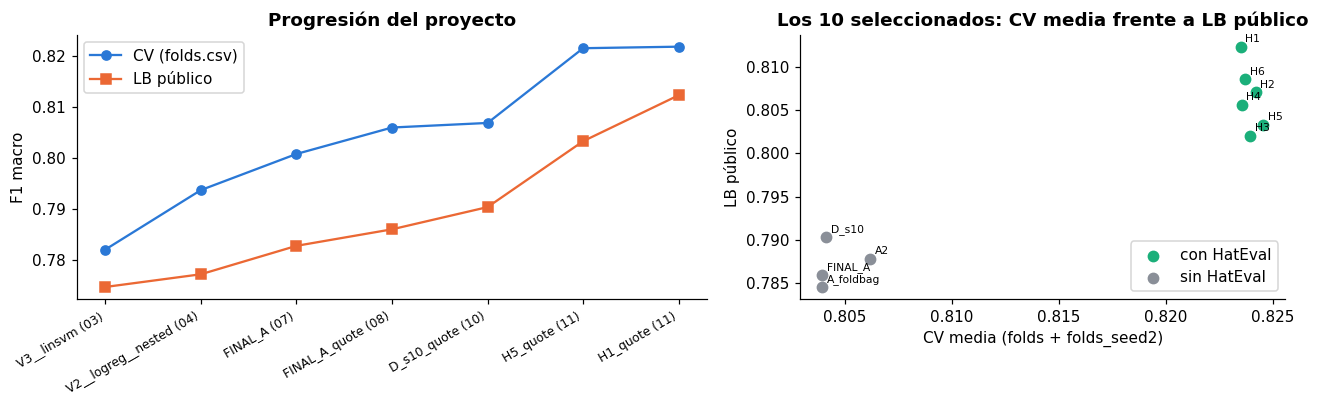

In [34]:
MILESTONES = [("V3__linsvm (03)", 0.782, 0.77464), ("V2__logreg__nested (04)", 0.7937, 0.77714), ("FINAL_A (07)", 0.8008, 0.78273),
              ("FINAL_A_quote (08)", 0.8060, 0.78598), ("D_s10_quote (10)", 0.8069, 0.79035), ("H5_quote (11)", 0.8216, 0.80331),
              ("H1_quote (11)", 0.8219, 0.81235)]  # CV en folds.csv (registro) y puntaje público de cada envío
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
names = [m[0] for m in MILESTONES]
axes[0].plot(range(len(names)), [m[1] for m in MILESTONES], "o-", color=COLORS["HS"], label="CV (folds.csv)")
axes[0].plot(range(len(names)), [m[2] for m in MILESTONES], "s-", color=COLORS["TR"], label="LB público")
axes[0].set_xticks(range(len(names)), names, rotation=30, ha="right", fontsize=8)
axes[0].set(title="Progresión del proyecto", ylabel="F1 macro")
axes[0].legend()
for has, color, label in ((True, COLORS["AG"], "con HatEval"), (False, COLORS["gris"], "sin HatEval")):
    s = SEL[(SEL["HatEval"] == "sí") == has]
    axes[1].scatter(s["CV media"], s["LB público"], color=color, label=label, s=45)
    for _, r in s.iterrows():
        axes[1].annotate(r["envío"].replace("_quote", ""), (r["CV media"], r["LB público"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[1].set(title="Los 10 seleccionados: CV media frente a LB público", xlabel="CV media (folds + folds_seed2)", ylabel="LB público")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretación:**
- **Los 10 seleccionados:**
  - **5 con HatEval admitidos por los criterios:** H5, H2, H6, H4 y H1;
  - **2 seguros sin HatEval:** A2_quote y FINAL_A_quote;
  - **3 huecos libres:** H3_quote (quedó 0.00028 por debajo del umbral de descarte del público, 0.80235), D_s10_quote y A_foldbag_quote.
- **Diversidad:** los candidatos con HatEval difieren entre sí en el 1.16–4.36% de las celdas, y de los sin HatEval en el 5.31–7.39%. Todos superan el mínimo del 1%: son decisiones realmente distintas.
- **Progresión del proyecto en el público:** 0.7746 (primer lineal) → 0.7860 (ensamble + regla) → 0.8124 (con HatEval).

## 11. Análisis de errores y limitaciones

**Errores del envío principal (H5_quote):** sus decisiones fuera de fold en `folds.csv`, tomadas del crossfit guardado. Se analizan los falsos positivos (FP) y negativos (FN) por etiqueta, y en qué tipo de tuits falla más.

In [35]:
E5 = art.ensembles["H5_quote"]
cf = art.crossfit[(art.crossfit["tag"] == "H5_quote") & (art.crossfit["foldset"] == "folds")].set_index("id").loc[train["id"]]
p5, f = cf[ks.P_COLS].to_numpy(), art.folds["folds"]
pred5 = np.zeros_like(Y)
for k in np.unique(f):
    v = f == k
    pred5[v] = en.decide(p5[v], E5["crossfit_thresholds"]["folds"][str(k)], True, EMPTY_TR[v], QUOTED[v])
display(pd.DataFrame([{"etiqueta": lab, "FP": int(((pred5[:, j] == 1) & (Y[:, j] == 0)).sum()),
                       "FN": int(((pred5[:, j] == 0) & (Y[:, j] == 1)).sum()), "F1 (OOF completa)": round(en.metrics(Y, pred5)[f"F1_{lab}"], 3)}
                      for j, lab in enumerate(LABELS)]).set_index("etiqueta"))
wrong = (pred5 != Y).any(axis=1)
groups_err = {"empieza con mención": starts_mention, "contiene un insulto del léxico": has_insult,
              "largo (> 140 caracteres)": length > 140, "con comillas (artefacto)": QUOTED}
display(pd.DataFrame([{"grupo": g, "% con algún error (sí)": round(100 * wrong[m].mean(), 1), "% con algún error (no)": round(100 * wrong[~m].mean(), 1),
                       "tuits (sí)": int(m.sum())} for g, m in groups_err.items()]).set_index("grupo"))
print(f"H5_quote acierta las 3 etiquetas en el {100 * (~wrong).mean():.1f}% de los tuits (OOF)")
fp = np.where((pred5[:, 0] == 1) & (Y[:, 0] == 0) & has_insult)[0]
fn = np.where((pred5[:, 0] == 0) & (Y[:, 0] == 1) & ~has_insult)[0]
show_ex = pd.concat([pd.DataFrame({"tipo": "FP de HS con insulto", "p(HS)": p5[fp, 0], "texto": texts.iloc[fp].to_numpy()}).nlargest(3, "p(HS)"),
                     pd.DataFrame({"tipo": "FN de HS sin insulto", "p(HS)": p5[fn, 0], "texto": texts.iloc[fn].to_numpy()}).nsmallest(3, "p(HS)")])
display(show_ex.round(3).set_index("tipo"))

,FP,FN,F1 (OOF completa)
etiqueta,,,
HS,186,109,0.814
TR,88,70,0.850
AG,172,107,0.799


,% con algún error (sí),% con algún error (no),tuits (sí)
grupo,,,
empieza con mención,16.8,28.3,701
contiene un insulto del léxico,19.0,29.8,982
largo (> 140 caracteres),31.4,21.7,347
con comillas (artefacto),25.5,23.6,51


H5_quote acierta las 3 etiquetas en el 76.3% de los tuits (OOF)


,p(HS),texto
tipo,,
FP de HS con insulto,0.976,@saancisco Callate puta tu eres el traidor.
FP de HS con insulto,0.971,@defays_mikael @rickcenturion cllate zorra ac los leprosos no opinan
FP de HS con insulto,0.970,@CamilaArvayo Cllate todo te queda bien zorra te amo
FN de HS sin insulto,0.023,Pues si la verdad si yo enseo la polla por internet aceptara con resignacin una violac...
FN de HS sin insulto,0.058,Imagnate si hubiera sido gero hubiera sido mas mamn
FN de HS sin insulto,0.059,m da miedo cuando me sigue un rabe


**Tuits que fallan los 10 modelos del ensamble original** (revisión manual del notebook 07): un tuit entra en la lista si los 10 modelos se equivocan en al menos una misma etiqueta. Se revisaron a mano los 20 que fallan en más etiquetas.

In [36]:
REVIEW = {  # revisión manual del notebook 07 (id -> categoría)
    20016: "insulto sin odio", 20082: "contexto ausente", 20273: "insulto sin odio", 20504: "insulto sin odio",
    20744: "vocabulario regional", 20799: "insulto sin odio", 20857: "etiqueta dudosa", 20952: "insulto sin odio",
    21050: "insulto sin odio", 21107: "insulto sin odio", 21150: "insulto sin odio", 21165: "insulto sin odio",
    21362: "contexto ausente", 21409: "ironía", 21497: "insulto sin odio", 21568: "insulto sin odio",
    21660: "objetivo ambiguo", 21892: "insulto sin odio", 22049: "contexto ausente", 22065: "contexto ausente"}
all_preds = np.stack([ks.crossfit_rule(art, [m], "single", Y, "folds", rule=False)[0]["pred"] for m in POOL_D])
all_wrong = (all_preds != Y[None]).all(axis=0)
hard = pd.DataFrame({"id": train["id"], "n": all_wrong.sum(axis=1), "real": combo, "texto": texts})
review = hard[hard["n"] > 0].sort_values(["n", "id"], ascending=[False, True]).head(20).set_index("id")
assert set(review.index) == set(REVIEW), "los 20 tuits no coinciden con la revisión manual del notebook 07"
pos_of = {i: n for n, i in enumerate(train["id"])}
review["mayoría del pool"] = ["".join(map(str, np.round(all_preds[:, pos_of[i]].mean(axis=0)).astype(int))) for i in review.index]
review["categoría"] = [REVIEW[i] for i in review.index]
print(f"Etiquetas que fallan los 10 modelos: {dict(zip(LABELS, all_wrong.sum(axis=0).tolist()))} | tuits con alguna: "
      f"{all_wrong.any(axis=1).sum()} ({100 * all_wrong.any(axis=1).mean():.1f}%)")
display(review["categoría"].value_counts().rename("tuits de 20").to_frame())
display(review[["real", "mayoría del pool", "categoría", "texto"]].head(8))

Etiquetas que fallan los 10 modelos: {'HS': 118, 'TR': 89, 'AG': 119} | tuits con alguna: 195 (11.3%)


,tuits de 20
categoría,
insulto sin odio,12
contexto ausente,4
vocabulario regional,1
etiqueta dudosa,1
ironía,1
objetivo ambiguo,1


,real,mayoría del pool,categoría,texto
id,,,,
20016,000,111,insulto sin odio,A Tomi Alegre JAKSKKSJSJ Cllate q tdv estoy de duelo puta https://t.co/ilHP09OzCK
20082,111,000,contexto ausente,Comemela XDDD y la cara tambin!! No nos pasemos https://t.co/t3o5yHY0zb
20273,000,111,insulto sin odio,@PedroArtZGFX @Smoshigames1999 Tu eres mio puta y te callas cabron
20504,000,111,insulto sin odio,@AldoGarFer Tu eres mi perra en beer pong
20744,111,000,vocabulario regional,Vecina chupa pija callate la boca que cantas horrible la puta que te pario
20799,000,111,insulto sin odio,Estoy tan tan feliz por mi amiga pochaa.. sos todo hija de perra. No te mueras nunca.T...
20857,111,000,etiqueta dudosa,Mis vecinos estaban escuchando msica al palo y pasaron de rabe a Do I Wanna Know? Lite...
20952,000,111,insulto sin odio,@NicolasMaduro Callate la jeta perra que de este ao no pasas


**Interpretación:**
- **Errores por exceso en HS y AG:** 186 y 172 falsos positivos frente a 109 y 107 falsos negativos. H5_quote acierta las 3 etiquetas en el 76.3% de los tuits (el ensamble sin HatEval, en el 72.4%).
- **Dónde falla más:** en los tuits sin mención (28.3% frente a 16.8%), sin insulto (29.8% frente a 19.0%) y largos (31.4% frente a 21.7%).
- **Falsos positivos más seguros: insultos sin odio**, como *"Callate puta tu eres el traidor"* (a un hombre, por política) o *"te queda bien zorra te amo"* (cariño entre amigas).
- **Falsos negativos más seguros: odio sin insultos**, por estereotipos (*"m da miedo cuando me sigue un rabe"*) o violencia sexual sin palabras ofensivas.
  - Además, el borrado de caracteres convierte *árabe* en *rabe* y *güero* en *gero*.
- **Los 10 modelos del ensamble original fallan juntos en 195 tuits (11.3%).** De los 20 revisados a mano:
  - 12 son insultos sin odio;
  - 4 dependen de un contexto ausente (imagen, meme, escena de televisión);
  - 1 etiqueta dudosa, 1 ironía, 1 objetivo ambiguo y 1 vocabulario regional.

**Limitaciones:**
- **La tarea:** el techo lo marca la definición de odio (contra mujeres e inmigrantes) frente al insulto genérico. Una representación de palabras no distingue la burla entre amigos del odio sin contexto.
- **Los datos:** 1731 tuits; las diferencias de CV menores de ≈0.005 son ruido.
- **HatEval:** la mejora depende de un corpus externo, autorizado y deduplicado. Su mezcla es algo distinta (tuits más largos y menos positivos), y su ganancia queda en la parte baja de lo previsto.
- **La regla de comillas** explota un artefacto del archivo. Se declaró, y afecta como mucho a 34 tuits del test.

## 12. Reproducción de los envíos

**Modo FAST.** Los 10 envíos se regeneran **sin entrenar ni cargar modelos**, a partir de dos elementos:
- **las probabilidades de test de sus modelos base**, guardadas en el dataset;
- **los parámetros de cada ensamble exportados a JSON:** coeficientes y escalado del stacker (o calibradores de Platt y pesos), umbrales, jerarquía HS=0 ⇒ TR=0, tuits vacíos ⇒ 000 y regla de comillas.

La reconstrucción desde el JSON da **exactamente** las mismas probabilidades que el objeto original (diferencia 0.0, comprobado al construir el dataset). La celda comprueba con `assert` que cada CSV regenerado es **idéntico** al que se envió a Kaggle.

**Archivos que se escriben:**
- `submission.csv`: **H5_quote**, el envío con mejor CV media;
- `submissions/`: los 10 envíos.

In [37]:
OUT_SUBS = WORK / "submissions"
check = ks.regenerate_submissions(art, OUT_SUBS)
display(check)
assert check["idéntico al enviado"].all() and (check["celdas distintas del enviado"] == 0).all() and (check["filas"] == len(test)).all()
main = pd.read_csv(OUT_SUBS / art.ensembles["H5_quote"]["file"])
assert list(main.columns) == ["id"] + LABELS and main["id"].tolist() == test["id"].tolist() and not main.isna().any().any()
assert set(np.unique(main[LABELS])) <= {0, 1}
main.to_csv(WORK / "submission.csv", index=False)
assert pd.read_csv(WORK / "submission.csv").equals(SUBS["H5_quote"])
print(f"submission.csv = H5_quote ({len(main)} filas; % de 1: " + ", ".join(f"{lab} {100 * main[lab].mean():.1f}" for lab in LABELS)
      + f") | 10 envíos en {OUT_SUBS.name}/, todos idénticos a los enviados")

,archivo,filas,ids en el orden del test,celdas distintas del enviado,idéntico al enviado
envío,,,,,
H5_quote,H5_quote_ens11__v2he05__weights__quote.csv,1154,True,0,True
H2_quote,H2_quote_ens11__v2he05__stack-all__quote.csv,1154,True,0,True
H6_quote,H6_quote_ens11__v2he05-new__stack-all__quote.csv,1154,True,0,True
H4_quote,H4_quote_ens11__mix05__stack-all__quote.csv,1154,True,0,True
H1_quote,H1_quote_ens11__v2he10__stack-all__quote.csv,1154,True,0,True
A2_quote,A2_quote_ens10__v2__stack-all__quote.csv,1154,True,0,True
FINAL_A_quote,FINAL_A_quote_ens08__D__stack-all__quote.csv,1154,True,0,True
H3_quote,H3_quote_ens11__Dhe05__stack-all__quote.csv,1154,True,0,True
D_s10_quote,D_s10_quote_ens10__Ds10__stack-all__quote.csv,1154,True,0,True


submission.csv = H5_quote (1154 filas; % de 1: HS 45.8, TR 30.4, AG 40.1) | 10 envíos en submissions/, todos idénticos a los enviados


**Reajuste del combinador en este entorno.** Como comprobación adicional, el ensamble de H5_quote se vuelve a ajustar desde las OOF de sus 14 modelos base, con la versión de scikit-learn instalada (crossfit completo).
- Con la misma versión del proyecto (scikit-learn 1.9.1), da exactamente la CV registrada.
- Con otras versiones, el optimizador de las regresiones logísticas internas (calibración de Platt) puede converger a coeficientes ligeramente distintos, y la CV se mueve unas milésimas.
- Los envíos no dependen de este reajuste: se regeneran con los parámetros exportados.

In [38]:
refit = {fs: ks.crossfit_rule(art, art.ensembles["H5_quote"]["cv_ids"], "weights", Y, fs)[1]["F1_macro"].mean() for fs in ("folds", "folds_seed2")}
for fs, v in refit.items():
    exp = art.ensembles["H5_quote"]["expected_cv"][fs]["F1_macro"]
    print(f"H5_quote [{fs}]: reajustado aquí {v:.4f} | registrado {exp:.4f} | diferencia {v - exp:+.4f}")
    if sklearn.__version__ == "1.9.1":
        assert abs(v - exp) <= 1e-4
    assert abs(v - exp) <= 0.01, "el reajuste se aleja más de lo esperable por la versión de scikit-learn"

H5_quote [folds]: reajustado aquí 0.8216 | registrado 0.8216 | diferencia -0.0000
H5_quote [folds_seed2]: reajustado aquí 0.8277 | registrado 0.8275 | diferencia +0.0002


**Modo FULL** (opcional; `MODE = "FULL"` en 1). Reentrena H5_quote desde los datos crudos con las **mismas funciones del proyecto** (`src/`):
1. **HatEval:** se descarga de Hugging Face en la revisión fijada, con el token `HF_TOKEN` de Kaggle Secrets, y se verifica el sha256 de cada archivo contra el manifest.
2. **Deduplicación** contra el train y el test (se comprueba que se conservan 3621 tuits).
3. **Los 14 modelos base:** CV en `folds.csv` con HatEval solo en entrenamiento (OOF) y modelos finales con todos los datos.
4. **Combinador** por pesos, umbrales de meseta y reglas.
5. **Comparación** con el CSV enviado.

**`SMOKE`** recorre el mismo camino con 1 fold, 1 semilla, rejillas mínimas y una submuestra, solo para comprobar que el código corre.

In [ ]:
if MODE in ("FULL", "SMOKE"):
    local = os.environ.get("TT_HATEVAL_LOCAL")  # copia local de HatEval: solo para la prueba fuera de Kaggle
    if IS_KAGGLE and not local and not os.environ.get("HF_TOKEN"):
        try:
            from kaggle_secrets import UserSecretsClient

            os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")  # no se imprime
        except Exception as exc:
            raise RuntimeError("Falta el secreto HF_TOKEN (Add-ons > Secrets) o Internet está desactivado") from exc
    FULL_RESULT = ks.run_full(MODE, art, WORK / MODE.lower(), hateval_local=local)
    display(pd.Series(FULL_RESULT, name=MODE).to_frame())
else:
    print("Modo FAST: no se reentrena nada. Para reentrenar H5_quote desde cero, MODE = 'FULL' en 1 (≈5–6 h).")
print(f"Tiempo total del notebook: {(time.perf_counter() - T0) / 60:.1f} min")

Modo FAST: no se reentrena nada. Para reentrenar H5_quote desde cero, MODE = 'FULL' en §1 (≈5–6 h).
Tiempo total del notebook: 0.4 min


## 13. Conclusiones y referencias

1. **La limpieza con minúsculas y los modelos lineales regularizados sobre TF-IDF de palabras y caracteres** fueron la base más fuerte con estos datos (0.790). Ni las redes, ni los árboles, ni el Transformer desde cero la superaron solos.
2. **El ensamble (stacking)** aportó +0.011 gracias a la diversidad de las redes. La regla del artefacto de comillas aportó +0.005 en CV y se confirmó en el leaderboard (+0.003).
3. **Agregar datos ayuda a generalizar y mejora el desempeño:** HatEval, deduplicado estrictamente, mejoró los 14 modelos y el ensamble en ≈+0.02.
   - Mejor CV: H5_quote, 0.8216 / 0.8275.
   - Mejor puntaje público: H1_quote, 0.81235.
4. **Se seleccionaron 10 envíos diversos con criterios fijados de antemano:** 6 con HatEval y 4 sin él. El leaderboard solo se usó para descartar y para el control de fuga.
5. **El límite está en la tarea:** distinguir los insultos sin odio del odio sin insultos. No es un problema de capacidad de los modelos.

**Referencias:**
- Basile, V., Bosco, C., Fersini, E., Nozza, D., Patti, V., Rangel Pardo, F. M., Rosso, P. y Sanguinetti, M. (2019). *SemEval-2019 Task 5: Multilingual Detection of Hate Speech Against Immigrants and Women in Twitter*. SemEval-2019, 54–63. https://aclanthology.org/S19-2007. Dataset `valeriobasile/HatEval` (Hugging Face), revisión `d170b5cb1844f3614493fce7c7eaaae087a5201c`, **CC BY-NC 4.0**.
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12. scikit-learn 1.9.1, BSD-3.
- Paszke, A. et al. (2019). *PyTorch*. NeurIPS. PyTorch 2.14.1 (CPU), BSD-3.
- Řehůřek, R. y Sojka, P. (2010). *Software Framework for Topic Modelling with Large Corpora* (gensim; Word2Vec entrenado desde cero). LGPL-2.1.
- Chen, T. y Guestrin, C. (2016). *XGBoost*. KDD. Apache-2.0. Ke, G. et al. (2017). *LightGBM*. NeurIPS. MIT.
- Honnibal, M. et al. spaCy 3.8 (MIT) y `es_core_news_sm` 3.8.0 (**GPL 3.0**; entrenado con UD Spanish AnCora y WikiNER). Solo lemas, categorías gramaticales y morfología, sin vectores.
- Hugging Face `tokenizers` 0.23 (Apache-2.0): solo el entrenador BPE, para entrenar un tokenizador propio desde cero.
- Wang, S. y Manning, C. (2012). *Baselines and Bigrams: Simple, Good Sentiment and Topic Classification* (NB-SVM). ACL.
- Monroe, B., Colaresi, M. y Quinn, K. (2008). *Fightin' Words* (log-odds con prior informativo). Political Analysis 16(4).
- Platt, J. (1999). *Probabilistic Outputs for Support Vector Machines*. Caruana, R. et al. (2004). *Ensemble Selection from Libraries of Models*. ICML.

Las versiones de este entorno se imprimen en §1. El proyecto se desarrolló con Python 3.14 y las versiones fijadas en `uv.lock`.

## Anexo: notebooks del proyecto (entregados aparte en el Campus Virtual)

| Notebook | Objetivo | Ejecución |
|---|---|---|
| 01_EDA | Exploración de datos: etiquetas, artefactos, borrado de no ASCII, léxico, spaCy, train frente a test | minutos |
| 02_preprocesamiento | 6 variantes de preprocesamiento, ablación y `TweetPreprocessor` | minutos |
| 03_modelos | Línea base: 3 clasificadores × 6 variantes (18 modelos) | minutos |
| 04_modelos_clasicos | Catálogo de 13 clasificadores, rasgos hechos a mano, CV anidada y diversidad | ≈40 min |
| 05_redes_neuronales | MLP, fastText, CNN, BiGRU y Word2Vec propios | ≈3 h 10 min |
| 06_transformer_desde_cero | Encoder Transformer con BPE propio y MLM dentro del fold | ≈2 h |
| 07_ensamble_final | Calibración, 6 métodos × 4 subconjuntos, `folds_seed2`, modelo final y análisis de errores | ≈17 min |
| 08_regla_artefacto_y_finales | Regla de comillas y envíos finales | ≈8 min |
| 09_mejoras | Curva de aprendizaje, especialización por etiqueta, 10 semillas y ensamble ampliado | ≈2.5 h |
| 10_candidatos_finales | Estrategia "mejor de 10" y 6 candidatos | ≈30 min |
| 11_hateval | HatEval: descarga fijada, deduplicación, 56 CV con pesos, candidatos H1–H6 y control de fuga | ≈8 h |